# Prepaid Card Marketing — Mini-Project 2
## Part 1 of 3: Data foundation (load, understand, clean, explore)

**Question.** Using the CFPB National Financial Well-Being Survey, which consumers are more likely to use a prepaid card, and what does that mean for (a) a card company's marketing and origination strategy and (b) the CFPB's protection of at-risk users?

**This notebook covers Steps 1–4 of the project plan.** Model building, evaluation and the two business answers follow in later parts and build on the cleaned file produced here.

| Step | Section | What it delivers |
|---|---|---|
| 1 | Setup and load | Data loaded and verified against the official CFPB codebook |
| 2 | Data understanding | Outcome definition, variable map, audit of special codes |
| 3 | Cleaning | Documented cleaning rules, a cleaned dataset and a variable-roles table |
| 4 | Exploration | Who uses prepaid cards, and which variables carry signal |

### Summary of this part

**Data quality**

- **The data is complete and verified.** 6,394 respondents and 217 variables. All 216 analysis variables reproduce the response count, range and weighted mean published in the official CFPB codebook.
- **Missing data was hidden as numbers.** 35,858 answers (2.6% of all cells, across 134 variables) were codes such as -1 "refused" or 99 "prefer not to say". All were converted to true missing values. One score with legitimate negative values (`KHscore`) was protected from that rule.
- **Three columns would have given the model the answer or the survey design, and were barred.** `PRODUSE_6` reveals the outcome outright (removed). `sample` and `PCTLT200FPL` encode which survey sample a person was drawn from (kept out of the predictor set).
- **The cleaned file has 6,367 respondents and 204 columns, of which 178 are candidate predictors.** 27 respondents who skipped more than 20% of the questionnaire were removed; no prepaid users were lost.

**What the data says about prepaid card users**

- **8.8% of respondents used a prepaid card** (560 people), about 1 user for every 10 non-users.
- **Use rises sharply with financial fragility.** 19.4% of households under \$20,000 income versus 3.5% at \$150,000 or more; 22.3% of people with \$0 in savings versus 4.8% with \$75,000 or more; 19.6% of people reporting no bank account versus 7.0% of those with one.
- **Low financial knowledge goes with higher use.** 17.6% in the lowest knowledge band versus 4.2% in the highest. Self-rated skill differs far less than tested knowledge.
- **Use is higher among younger adults and among Black and Hispanic respondents** (18–24: 12.8%; Black: 18.6%; Hispanic: 15.7%; White: 6.0%).
- **Most users are not unbanked or poor.** 68% of prepaid users have a bank account and 62% have household income of \$30,000 or more. The high-rate groups are small; the bulk of users sit in the mainstream.
- **No single variable is a strong predictor** (the strongest association is 0.19 on a 0–1 scale), but 141 of the 178 candidates carry a statistically reliable signal. Prediction will come from combining many overlapping, modest signals.
- **The findings are not an artefact of the survey's oversamples.** Repeating the screening on the general-population sample alone gives almost the same ranking (rank correlation 0.97).

---
# 1. Setup and load

In [1]:
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60, "display.width", 200, "display.max_colwidth", 90)

# ---- Paths -------------------------------------------------------------------
DATA_DIR = Path("data")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
RAW_PATH = DATA_DIR / "CFPB-financial-wellness-data.csv"      # survey data as supplied
CODEBOOK_PATH = DATA_DIR / "codebook_reference.csv"           # labels + published summary stats from the CFPB codebook
CLEAN_PATH = DATA_DIR / "cfpb_clean.csv"                      # output of Section 3
ROLES_PATH = DATA_DIR / "variable_roles.csv"                  # output of Section 3

TARGET = "PRODUSE_3"   # 1 = used a reloadable prepaid card not linked to a checking or savings account
SEED = 42

# ---- Chart style (one consistent look for every figure) -----------------------
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
SEQ_CMAP = LinearSegmentedColormap.from_list("seq_blue", ["#e6f0fd", "#86b6ef", "#2a78d6", "#104281"])
DIV_CMAP = LinearSegmentedColormap.from_list("div", [ORANGE, "#f0efec", BLUE])

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "text.color": INK, "axes.labelcolor": INK2,
    "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 10,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.7,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.frameon": False, "legend.fontsize": 9,
})



def fmt(df, formats, hide_index=False):
    """Return a display copy of a table with numbers formatted as text (no extra packages needed)."""
    out = df.copy()
    if isinstance(formats, str):
        formats = {c: formats for c in out.columns if pd.api.types.is_numeric_dtype(out[c])}
    for col, pattern in formats.items():
        if col in out.columns:
            out[col] = out[col].map(lambda v, p=pattern: p.format(v) if pd.notna(v) else "")
    return out.reset_index(drop=True) if hide_index else out


print(f"pandas {pd.__version__} | numpy {np.__version__} | matplotlib {mpl.__version__}")

pandas 3.0.6 | numpy 2.5.3 | matplotlib 3.11.2


### 1.1 Load the survey data

The data was supplied as a PDF print-out of the CSV. It was converted back to a table once, saved as `data/CFPB-financial-wellness-data.csv`, and is loaded from there. Section 1.3 proves the conversion was lossless.

In [2]:
raw = pd.read_csv(RAW_PATH)
codebook = pd.read_csv(CODEBOOK_PATH).set_index("variable")

print(f"Respondents (rows): {raw.shape[0]:,}")
print(f"Variables (columns): {raw.shape[1]}")
raw.iloc[:5, :14]

Respondents (rows): 6,394
Variables (columns): 217


,PUF_ID,sample,fpl,SWB_1,SWB_2,SWB_3,FWBscore,FWB1_1,FWB1_2,FWB1_3,FWB1_4,FWB1_5,FWB1_6,FWB2_1
0,10350,2,3,5,5,6,55,3,3,3,3,2,3,2
1,7740,1,3,6,6,6,51,2,2,3,3,3,4,2
2,13699,1,3,4,3,4,49,3,3,3,3,3,3,3
3,7267,1,3,6,6,6,49,3,3,3,3,3,3,3
4,7375,1,3,4,4,4,49,3,3,3,3,3,3,3


### 1.2 Structural integrity checks

In [3]:
integrity = {
    "Row count equals the codebook's 6,394 respondents": len(raw) == 6394,
    "Column count equals the codebook's 217 variables": raw.shape[1] == 217,
    "Column names and order match the codebook": list(raw.columns) == list(codebook.index),
    "Respondent ID (PUF_ID) is unique": raw["PUF_ID"].is_unique,
    "No blank cells": bool(raw.notna().all().all()),
    "Every column is numeric": all(pd.api.types.is_numeric_dtype(t) for t in raw.dtypes),
    "No two respondents have identical answers": not raw.drop(columns="PUF_ID").duplicated().any(),
    "Outcome PRODUSE_3 contains only 0 and 1": set(raw[TARGET].unique()) == {0, 1},
}
display(pd.DataFrame({"Check": list(integrity), "Result": ["PASS" if ok else "FAIL" for ok in integrity.values()]}))
assert all(integrity.values()), "Structural integrity check failed"

,Check,Result
0,"Row count equals the codebook's 6,394 respondents",PASS
1,Column count equals the codebook's 217 variables,PASS
2,Column names and order match the codebook,PASS
3,Respondent ID (PUF_ID) is unique,PASS
4,No blank cells,PASS
5,Every column is numeric,PASS
6,No two respondents have identical answers,PASS
7,Outcome PRODUSE_3 contains only 0 and 1,PASS


### 1.3 Validation against the official CFPB codebook

The codebook publishes, for every variable, the number of substantive responses, the minimum, the maximum and the survey-weighted mean. Reproducing all four for every column is a cell-level proof that the file is the genuine public-use dataset and that nothing was corrupted in conversion.

The survey weight `finalwt` is used **only** for this check. The project brief says to ignore weights for the analysis, and they are not used anywhere else.

In [4]:
# Positive codes that the codebook treats as non-substantive ("don't know", "prefer not to say", "not sure")
POSITIVE_NONRESPONSE = {
    "HOUSERANGES": [98, 99], "VALUERANGES": [98, 99], "MORTGAGE": [98, 99], "SAVINGSRANGES": [98, 99],
    "SNAP": [8], "COLLECT": [8], "ABSORBSHOCK": [8], "FRAUD2": [8],
    "EMPLOY": [99],
}


def codebook_substantive(col):
    """Values the codebook counts as substantive for its published summary table."""
    s = raw[col]
    keep = pd.Series(True, index=s.index) if col == "finalwt" else (s >= 0)
    keep &= ~s.isin(POSITIVE_NONRESPONSE.get(col, []))
    if col.startswith("EMPLOY1_"):
        keep &= raw["EMPLOY1_9"] == 0      # respondents who ticked no employment box are non-substantive
    return s[keep]


rows = []
for col in raw.columns.drop("PUF_ID"):
    s, ref = codebook_substantive(col), codebook.loc[col]
    mean = s.mean() if col == "finalwt" else np.average(s, weights=raw.loc[s.index, "finalwt"])
    rows.append({
        "variable": col,
        "count_matches": len(s) == ref["cb_n_valid"],
        "range_matches": bool(np.isclose(s.min(), ref["cb_min"], atol=2e-3) and np.isclose(s.max(), ref["cb_max"], atol=2e-3)),
        "weighted_mean_matches": abs(mean - ref["cb_weighted_mean"]) <= 6e-4,
    })
validation = pd.DataFrame(rows).set_index("variable")

summary = pd.DataFrame({
    "Variables checked": len(validation),
    "Reproduced": validation.sum(),
    "Not reproduced": (~validation).sum(),
}).rename(index={"count_matches": "Number of substantive responses",
                 "range_matches": "Minimum and maximum",
                 "weighted_mean_matches": "Survey-weighted mean (to 3 decimals)"})
display(summary)
assert validation.all().all(), "Data does not reproduce the codebook"
print(f"All {len(validation)} variables reproduce the codebook's published count, range and weighted mean.")

,Variables checked,Reproduced,Not reproduced
Number of substantive responses,216,216,0
Minimum and maximum,216,216,0
Survey-weighted mean (to 3 decimals),216,216,0


All 216 variables reproduce the codebook's published count, range and weighted mean.


**Result.** The file is confirmed as the complete, uncorrupted CFPB public-use dataset: every one of the 216 analysis variables reproduces the codebook's published response count, range and weighted mean.

---
# 2. Data understanding

### 2.1 What the dataset is

- **Source:** CFPB National Financial Well-Being Survey, Public Use File (fielded 2016, codebook dated September 2017). The codebook is saved in `docs/cfpb_nfwbs-puf-codebook.pdf`.
- **Unit of analysis:** one row per adult respondent (6,394 people).
- **Content:** 217 variables covering financial well-being, skills, knowledge, behaviours, products, hardship, attitudes and demographics.
- **Encoding:** every value is a number, but almost every column is a *coded survey answer* (for example 1 = "Never" … 5 = "Always"), not a quantity. Only a handful are true scores.
- **Sample design:** three samples are pooled, a general-population sample plus two deliberate oversamples (adults aged 62+, and a race/ethnicity and poverty oversample). This matters for interpreting raw rates and is examined in 2.2.

### 2.2 The outcome variable

`PRODUSE_3` — *"Used reloadable card not linked with checking or savings account"* (1 = Yes, 0 = No). It is one of five tick-boxes in a single "which of these have you used" question about non-bank financial products.

In [5]:
def wilson_interval(k, n, z=1.96):
    """95% Wilson confidence interval for a proportion (well-behaved for small groups and rare outcomes)."""
    k, n = np.asarray(k, dtype=float), np.asarray(n, dtype=float)
    p = k / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre - half, centre + half


n_users, n_total = int(raw[TARGET].sum()), len(raw)
BASE_RATE = n_users / n_total
lo, hi = wilson_interval(n_users, n_total)
weighted_rate = np.average(raw[TARGET], weights=raw["finalwt"])

display(pd.DataFrame({
    "Respondents": [n_total - n_users, n_users, n_total],
    "Share": [f"{1 - BASE_RATE:.1%}", f"{BASE_RATE:.1%}", "100.0%"],
}, index=["Did not use a prepaid card (0)", "Used a prepaid card (1)", "Total"]))
print(f"Prepaid card usage rate: {BASE_RATE:.2%} (95% CI {lo:.1%} to {hi:.1%})")
print(f"Class imbalance: 1 user for every {(n_total - n_users) / n_users:.1f} non-users")
print(f"For context only: the survey-weighted national estimate is {weighted_rate:.1%} (weights are not used in this analysis)")

,Respondents,Share
Did not use a prepaid card (0),5834,91.2%
Used a prepaid card (1),560,8.8%
Total,6394,100.0%


Prepaid card usage rate: 8.76% (95% CI 8.1% to 9.5%)
Class imbalance: 1 user for every 10.4 non-users
For context only: the survey-weighted national estimate is 10.1% (weights are not used in this analysis)


In [6]:
SAMPLE_LABELS = {1: "General population", 2: "Age 62+ oversample", 3: "Race/ethnicity and poverty oversample"}
by_sample = raw.groupby("sample")[TARGET].agg(n="size", users="sum")
by_sample["rate"] = by_sample["users"] / by_sample["n"]
by_sample["ci_low"], by_sample["ci_high"] = wilson_interval(by_sample["users"], by_sample["n"])
by_sample.index = by_sample.index.map(SAMPLE_LABELS)
fmt(by_sample, {"n": "{:,}", "rate": "{:.1%}", "ci_low": "{:.1%}", "ci_high": "{:.1%}"})

,n,users,rate,ci_low,ci_high
sample,,,,,
General population,"5,000",421,8.4%,7.7%,9.2%
Age 62+ oversample,999,59,5.9%,4.6%,7.5%
Race/ethnicity and poverty oversample,395,80,20.3%,16.6%,24.5%


**Takeaways**

- **The outcome is imbalanced:** 8.8% users, about 1 to 10. A model that predicts "no one uses a prepaid card" would be 91.2% accurate and useless. Later steps therefore use a stratified train/test split, class weighting, and metrics that reward finding users (recall, precision, precision-recall AUC, lift) in place of plain accuracy.
- **The usage rate depends on which sample a respondent came from:** 8.4% in the general-population sample, 5.9% in the age 62+ oversample and 20.3% in the race/ethnicity and poverty oversample. Two consequences:
  1. The pooled 8.8% is not a national estimate (the weighted figure is 10.1%). The brief asks for unweighted analysis, so 8.8% is the working base rate.
  2. `sample` would look predictive in a model, but it describes the survey, not the person. It is barred from the predictor set in Section 3.

### 2.3 Variable map

The 217 variables fall into 13 thematic groups. The grouping is used throughout to keep the analysis balanced across themes.

In [7]:
GROUP_RULES = [
    ("Administrative (ID, design, weight)",        r"^(PUF_ID|sample|finalwt|IMPUTATION_FLAG)$"),
    ("Outcome and same-question items",            r"^PRODUSE_"),
    ("Financial well-being",                       r"^(SWB_|FWBscore|FWB1_|FWB2_)"),
    ("Financial skill and self-assessed ability",  r"^(FSscore|FS1_|FS2_|SUBKNOWL1|SUBNUMERACY|GOALCONF|CHANGEABLE)"),
    ("Financial knowledge and numeracy (tested)",  r"^(LMscore|FINKNOWL|FK\dcorrect|KHscore|KHKNOWL|KH\dcorrect|OBJNUMERACY1|ON\dcorrect)"),
    ("Money management behaviour",                 r"^(ACT1_|FINGOALS|PROPPLAN_|MANAGE1_|MANAGE2|PAIDHELP|SAVEHABIT|FRUGALITY|AUTOMATED_|ASK1_|SCFHORIZON|COVERCOSTS|INTERCONNECTIONS_)"),
    ("Financial products held",                    r"^PRODHAVE_"),
    ("Financial strain, hardship and shocks",      r"^(ENDSMEET|MATHARDSHIP_|COLLECT|REJECTED_|ABSORBSHOCK|SHOCKS_|VOLATILITY|SNAP|BORROW_|FRAUD2|CONSPROTECT)"),
    ("Housing, savings and household resources",   r"^(HOUSING|LIVINGARRANGEMENT|HOUSERANGES|VALUERANGES|MORTGAGE|SAVINGSRANGES|HOUSESAT|EARNERS|BENEFITS_)"),
    ("Attitudes, traits and health",               r"^(MATERIALISM_|CONNECT|HEALTH|DISCOUNT|MEMLOSS|DISTRESS|SELFCONTROL_|OUTLOOK_|PEM|LIFEEXPECT)"),
    ("Upbringing",                                 r"^(HSLOC|PAREDUC|FINSOC2_)"),
    ("Employment, retirement and military",        r"^(EMPLOY|RETIRE|SOCSEC|MILITARY|Military_Status)"),
    ("Demographics and geography",                 r"^(agecat|generation|PP|fpl|HHEDUC|KIDS_|PCTLT200FPL)"),
]


def variable_group(name):
    for group, pattern in GROUP_RULES:
        if re.match(pattern, name):
            return group
    return "Derived in this notebook"


groups = pd.Series({c: variable_group(c) for c in raw.columns}, name="group")
assert (groups != "Derived in this notebook").all(), "A raw variable has no group"

group_table = (groups.reset_index().rename(columns={"index": "variable"})
               .groupby("group", sort=False)["variable"]
               .agg(variables="size", examples=lambda v: ", ".join(list(v)[:5]) + (" …" if len(v) > 5 else "")))
group_table = group_table.loc[[g for g, _ in GROUP_RULES]]
display(group_table)
print("Total variables:", int(group_table["variables"].sum()))

,variables,examples
group,,
"Administrative (ID, design, weight)",4,"PUF_ID, sample, IMPUTATION_FLAG, finalwt"
Outcome and same-question items,6,"PRODUSE_1, PRODUSE_2, PRODUSE_3, PRODUSE_4, PRODUSE_5 …"
Financial well-being,14,"SWB_1, SWB_2, SWB_3, FWBscore, FWB1_1 …"
Financial skill and self-assessed ability,16,"FSscore, FS1_1, FS1_2, FS1_3, FS1_4 …"
Financial knowledge and numeracy (tested),29,"LMscore, FINKNOWL1, FINKNOWL2, FINKNOWL3, FK1correct …"
Money management behaviour,31,"ACT1_1, ACT1_2, FINGOALS, PROPPLAN_1, PROPPLAN_2 …"
Financial products held,9,"PRODHAVE_1, PRODHAVE_2, PRODHAVE_3, PRODHAVE_4, PRODHAVE_5 …"
"Financial strain, hardship and shocks",31,"ENDSMEET, CONSPROTECT1, CONSPROTECT2, CONSPROTECT3, VOLATILITY …"
"Housing, savings and household resources",13,"HOUSING, LIVINGARRANGEMENT, HOUSERANGES, VALUERANGES, MORTGAGE …"


Total variables: 217


### 2.4 Special codes: where missing data hides

The file has no blank cells, but that is misleading. Non-answers are stored as **numbers that look like data**. Used as-is, they would be read by a model as real values (for example, "prefer not to say" coded 99 on a 1–7 savings scale would look like enormous savings).

The codebook defines these codes:

| Code | Meaning | Nature |
|---|---|---|
| -1 | Refused | Respondent chose not to answer |
| -2 | Question not asked, respondent not in the item's base | Skip logic, the question did not apply |
| -3 | Invalid response | Processing |
| -4 | Response not written to database | Processing |
| -5 | County is not known | Processing |
| 8 | "Not sure" / "I don't know" / "I can't recall" (5 variables) | Respondent did not know |
| 98 | "I don't know" (4 dollar-range variables) | Respondent did not know |
| 99 | "Prefer not to say" (4 dollar-range variables), "Refused" (`EMPLOY`) | Respondent chose not to answer |

**One important exception:** `KHscore` (a financial-knowledge score) is a standardised score whose legitimate values run from -2.053 to 1.267. A blanket "negative means missing" rule would wrongly delete most of it. It is explicitly protected below.

In [8]:
NEGATIVE_IS_VALID = ["KHscore"]                       # legitimate negative values, never treated as missing
# Questions asked of a subgroup only (homeowners, retirees, people aged 62+ ...): code -2 marks everyone else
CONDITIONAL = ["VALUERANGES", "MORTGAGE", "PAIDHELP", "SOCSEC1", "SOCSEC2", "SOCSEC3", "LIFEEXPECT", "RETIRE"]
# Our rule set = the codebook's rules plus one judgement call: HSLOC code 8 ("I can't recall") carries no information.
NONRESPONSE_CODES = {**POSITIVE_NONRESPONSE, "HSLOC": [8]}

CODE_MEANING = {-1: "Refused", -2: "Not asked (skip logic)", -3: "Invalid response", -4: "Not written to database",
                -5: "County not known", 8: "Don't know / not sure", 98: "Don't know", 99: "Prefer not to say / refused"}
CODE_NATURE = {-1: "Chose not to answer", 99: "Chose not to answer", 8: "Did not know", 98: "Did not know",
               -2: "Not asked (skip logic)", -3: "Processing", -4: "Processing", -5: "Processing"}

audit_rows = []
for col in raw.columns.drop(["PUF_ID", "finalwt"]):
    s = raw[col]
    codes = ([] if col in NEGATIVE_IS_VALID else sorted(s[s < 0].unique().tolist())) + NONRESPONSE_CODES.get(col, [])
    for code in codes:
        n = int((s == code).sum())
        if n:
            audit_rows.append({"variable": col, "code": int(code), "cells": n})
audit = pd.DataFrame(audit_rows)
audit["meaning"] = audit["code"].map(CODE_MEANING)
audit["nature"] = audit["code"].map(CODE_NATURE)

code_summary = (audit.groupby(["code", "meaning"])
                .agg(variables_affected=("variable", "nunique"), cells=("cells", "sum")).reset_index())
code_summary["share_of_all_cells"] = code_summary["cells"] / (raw.shape[0] * (raw.shape[1] - 2))
display(fmt(code_summary, {"cells": "{:,}", "share_of_all_cells": "{:.2%}"}, hide_index=True))

total_special = int(audit["cells"].sum())
print(f"Hidden non-answers: {total_special:,} cells across {audit['variable'].nunique()} variables "
      f"({total_special / (raw.shape[0] * (raw.shape[1] - 2)):.1%} of all cells).")
print(f"Variables with no special codes at all: {raw.shape[1] - 2 - audit['variable'].nunique()}")

,code,meaning,variables_affected,cells,share_of_all_cells
0,-5,County not known,1,395,0.03%
1,-4,Not written to database,14,14,0.00%
2,-3,Invalid response,3,235,0.02%
3,-2,Not asked (skip logic),8,"23,817",1.73%
4,-1,Refused,132,"7,162",0.52%
5,8,Don't know / not sure,5,"1,215",0.09%
6,98,Don't know,4,635,0.05%
7,99,Prefer not to say / refused,5,"2,385",0.17%


Hidden non-answers: 35,858 cells across 134 variables (2.6% of all cells).
Variables with no special codes at all: 81


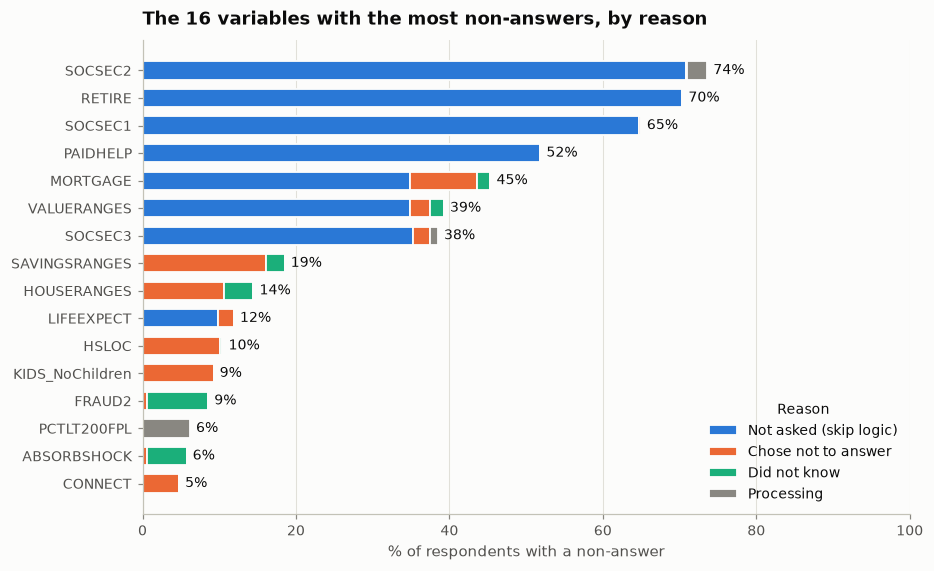

In [9]:
# Which variables are most affected, and why?
nature_order = ["Not asked (skip logic)", "Chose not to answer", "Did not know", "Processing"]
nature_colors = dict(zip(nature_order, [BLUE, ORANGE, AQUA, MUTED]))
by_var = (audit.pivot_table(index="variable", columns="nature", values="cells", aggfunc="sum", fill_value=0)
          .reindex(columns=nature_order, fill_value=0) / len(raw) * 100)
top = by_var.assign(total=by_var.sum(axis=1)).sort_values("total").tail(16)

fig, ax = plt.subplots(figsize=(9, 5.6))
left = np.zeros(len(top))
for nature in nature_order:
    ax.barh(top.index, top[nature], left=left, color=nature_colors[nature], label=nature,
            height=0.66, edgecolor=SURFACE, linewidth=1.2)
    left += top[nature].to_numpy()
for y, total in enumerate(top["total"]):
    ax.text(total + 0.8, y, f"{total:.0f}%", va="center", fontsize=9, color=INK)
ax.set_xlim(0, 100)
ax.set_xlabel("% of respondents with a non-answer")
ax.set_title("The 16 variables with the most non-answers, by reason")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", title="Reason", title_fontsize=9)
fig.savefig(FIG_DIR / "01_special_codes_by_variable.png")
plt.show()

**Takeaways**

- **35,858 cells (2.6%) are non-answers stored as numbers**, spread over 134 of the 215 analysis columns. 81 columns have none.
- **Two-thirds of them (23,817) are skip logic**, concentrated in eight follow-up questions that were only asked of a subgroup, such as homeowners (`MORTGAGE`, `VALUERANGES`), retirees (`RETIRE`) or people aged 62+ (`SOCSEC1–3`). These are "not applicable", not refusals.
- **Genuine non-response is low for most questions** (under 2%), with a few exceptions: 19% did not state their savings and 14% did not state their housing cost.
- `PCTLT200FPL` (county poverty rate) is unknown for 6% of respondents. Section 3.8 shows these are exactly the oversample respondents.

---
# 3. Cleaning

Every cleaning decision is stated, justified and logged. The rules are applied in a fixed order and the log is printed at the end of the section.

**Principles**

1. **Never alter the raw file.** All changes are made on a copy; the raw data stays available for audit.
2. **Follow the codebook** for what counts as a non-answer; flag any place where we go beyond it.
3. **Prevent leakage.** Remove anything that mechanically reveals the outcome.
4. **Preserve information.** Where the act of not answering may itself be informative, keep a flag for it.
5. **Do not fit anything here.** Imputation and standardisation depend on the data they are fitted to, so they belong inside the modelling pipeline (fitted on training data only). Doing them here would leak test-set information into the models.

In [10]:
clean = raw.set_index("PUF_ID").astype("float64")
cleaning_log = []


def log_step(step, action, detail):
    cleaning_log.append({"Step": step, "Action": action, "Effect": detail})


print("Working copy:", clean.shape)

Working copy: (6394, 216)


### 3.1 Capture informative non-response before removing it

For most variables fewer than 2% of respondents gave a non-answer, and treating those as missing loses nothing. A few variables are different: 15–19% of respondents declined to state their savings or housing cost. Declining may itself say something about a person, so for any variable where **at least 5%** of respondents refused or did not know, a companion flag `<VARIABLE>_NR` (1 = non-response) is created. Whether these flags carry signal is tested in Section 4.6.

Skip-logic codes (-2) are not counted here: a question that was never asked is not a refusal.

In [11]:
NR_THRESHOLD = 0.05
voluntary = audit[audit["nature"].isin(["Chose not to answer", "Did not know"])]
nr_share = voluntary[~voluntary["variable"].isin(CONDITIONAL)].groupby("variable")["cells"].sum() / len(raw)
nr_flag_vars = nr_share[nr_share >= NR_THRESHOLD].sort_values(ascending=False)

raw_by_id = raw.set_index("PUF_ID")
flags = pd.DataFrame({
    f"{col}_NR": raw_by_id[col].isin(voluntary.loc[voluntary["variable"] == col, "code"].tolist()).astype(float)
    for col in nr_flag_vars.index})
clean = pd.concat([clean, flags], axis=1)

display(pd.DataFrame({"label": codebook.loc[nr_flag_vars.index, "codebook_label"],
                      "share_refused_or_dont_know": nr_flag_vars.map("{:.1%}".format),
                      "flag_created": [f"{c}_NR" for c in nr_flag_vars.index]}))
log_step("3.1", "Created non-response flags for variables with >= 5% refused / don't know",
         f"{len(nr_flag_vars)} flag columns added")

,label,share_refused_or_dont_know,flag_created
variable,,,
SAVINGSRANGES,How much money do you have in savings today...?,18.5%,SAVINGSRANGES_NR
HOUSERANGES,About how much do you pay for your home each month?,14.5%,HOUSERANGES_NR
HSLOC,Where did you live at age 17?,10.4%,HSLOC_NR
KIDS_NoChildren,I have no children that I support financially,9.3%,KIDS_NoChildren_NR
FRAUD2,Victim of financial fraud or attempted financial fraud in past 5 years,8.6%,FRAUD2_NR
ABSORBSHOCK,"Confidence in ability to raise $2,000 in 30 days",5.7%,ABSORBSHOCK_NR


### 3.2 Recode non-answers to missing

All special codes from Section 2.4 are converted to true missing values (`NaN`):

- every negative code, in every column **except `KHscore`**;
- 98 and 99 in the four dollar-range variables, 8 in the five "not sure" variables, 99 in `EMPLOY`;
- the eight employment tick-boxes (`EMPLOY1_1`–`EMPLOY1_8`) for the 116 respondents who ticked none of them (the codebook treats these as non-response, not as eight "No" answers).

For the other tick-box questions (products held, shocks, advice sources) the codebook treats "nothing ticked" as a valid "none of these", so those zeros are kept.

In [12]:
before_missing = int(clean.isna().sum().sum())

# (a) negative codes, with KHscore protected
neg_cols = [c for c in raw.columns if c not in ["PUF_ID", "finalwt"] + NEGATIVE_IS_VALID]
n_negative = int((clean[neg_cols] < 0).sum().sum())
clean[neg_cols] = clean[neg_cols].mask(clean[neg_cols] < 0)

# (b) positive non-response codes
n_positive = 0
for col, codes in NONRESPONSE_CODES.items():
    hit = clean[col].isin(codes)
    n_positive += int(hit.sum())
    clean[col] = clean[col].mask(hit)

# (c) employment tick-boxes for respondents who ticked nothing
employ_boxes = [f"EMPLOY1_{i}" for i in range(1, 9)]
no_employment_answer = clean["EMPLOY1_9"] == 1
clean.loc[no_employment_answer, employ_boxes] = np.nan
n_employ = int(no_employment_answer.sum()) * len(employ_boxes)

after_missing = int(clean.isna().sum().sum())
assert after_missing - before_missing == n_negative + n_positive + n_employ
assert after_missing - before_missing - n_employ == total_special, "Recode does not match the Section 2.4 audit"
assert (clean.drop(columns=NEGATIVE_IS_VALID) < 0).sum().sum() == 0, "A negative code survived"
assert clean["KHscore"].notna().all() and np.isclose(clean["KHscore"].min(), -2.053), "KHscore was damaged"

print(f"Negative codes recoded to missing:        {n_negative:>7,}")
print(f"Positive non-response codes recoded:      {n_positive:>7,}")
print(f"Employment tick-boxes set to missing:     {n_employ:>7,}")
print(f"Total cells now missing:                  {after_missing:>7,}")
print(f"KHscore untouched: {clean['KHscore'].notna().sum():,} valid values, range {clean['KHscore'].min()} to {clean['KHscore'].max()}")
log_step("3.2", "Recoded special codes to missing (KHscore protected)",
         f"{after_missing:,} cells set to NaN across {int((clean.isna().sum() > 0).sum())} columns")

Negative codes recoded to missing:         31,623
Positive non-response codes recoded:        4,235
Employment tick-boxes set to missing:         928
Total cells now missing:                   36,786
KHscore untouched: 6,394 valid values, range -2.053 to 1.267


### 3.3 Remove target leakage

`PRODUSE_6` records "respondent did not select any item" in the same tick-box question that contains the outcome. Anyone flagged there cannot, by construction, have ticked the prepaid card box. It is not a predictor, it is the answer sheet.

In [13]:
leak = pd.crosstab(raw["PRODUSE_6"].map({0: "PRODUSE_6 = 0 (ticked at least one product)", 1: "PRODUSE_6 = 1 (ticked none)"}),
                   raw[TARGET].map({0: "Did not use prepaid", 1: "Used prepaid"}))
leak["Usage rate"] = (leak["Used prepaid"] / leak.sum(axis=1)).map("{:.1%}".format)
display(leak)
assert raw.loc[raw["PRODUSE_6"] == 1, TARGET].sum() == 0

clean = clean.drop(columns="PRODUSE_6")
log_step("3.3", "Dropped PRODUSE_6 (deterministic leakage of the outcome)", "1 column removed")

PRODUSE_3,Did not use prepaid,Used prepaid,Usage rate
PRODUSE_6,,,
PRODUSE_6 = 0 (ticked at least one product),741,560,43.0%
PRODUSE_6 = 1 (ticked none),5093,0,0.0%


The four **other** boxes in that question (`PRODUSE_1` payday loan, `PRODUSE_2` pawn or auto-title loan, `PRODUSE_4` non-bank international transfer, `PRODUSE_5` non-bank cheque cashing or money order) are not deterministic leakage, but they were answered in the same breath as the outcome and describe the same behaviour family. They are **kept in the cleaned file but marked "restricted"**: useful for describing users (Section 4.5), with a recommendation to keep them out of the predictive model unless the business case is specifically cross-selling to existing users of alternative financial services. That decision is formally taken at feature selection (Step 5).

### 3.4 Remove administrative columns

- `finalwt` — survey weight. The brief says to ignore weights.
- `IMPUTATION_FLAG` — paradata recording that the CFPB imputed `HOUSERANGES`; not a respondent characteristic.
- `sample` — which sample the respondent was drawn from. It is a property of the survey design, not of the person, and would not exist for a real prospect. It is **kept for diagnostics only** and barred from the predictor set.

In [14]:
clean = clean.drop(columns=["finalwt", "IMPUTATION_FLAG"])
log_step("3.4", "Dropped survey weight and imputation paradata", "2 columns removed; `sample` kept for diagnostics only")

### 3.5 Remove columns that duplicate other columns exactly

Two families of columns add no information because another column already contains it. Each claim is verified in code before anything is dropped.

- **Raw quiz answers** (`FINKNOWL1–3`, `KHKNOWL1–9`, `OBJNUMERACY1`). These store *which option* was picked (for example 1 = "More than \$102"). The companion `…correct` columns already store whether the answer was right, which is the meaningful part.
- **"Nothing ticked" indicators** (`PRODHAVE_9`, `SHOCKS_12`, `INTERCONNECTIONS_10`, `EMPLOY1_9`). Each is simply "all the other boxes are 0".

In [15]:
quiz_pairs = {**{f"FINKNOWL{i}": f"FK{i}correct" for i in range(1, 4)},
              **{f"KHKNOWL{i}": f"KH{i}correct" for i in range(1, 10)},
              "OBJNUMERACY1": "ON1correct"}
# The 'correct' flag must be a pure function of the raw answer: one flag value per answer option.
quiz_ok = all(raw.groupby(item)[flag].nunique().max() == 1 for item, flag in quiz_pairs.items())

none_ticked = {"PRODHAVE_9": [f"PRODHAVE_{i}" for i in range(1, 9)],
               "SHOCKS_12": [f"SHOCKS_{i}" for i in range(1, 12)],
               "INTERCONNECTIONS_10": [f"INTERCONNECTIONS_{i}" for i in range(1, 10)],
               "EMPLOY1_9": employ_boxes}
none_ok = all(((raw[boxes].sum(axis=1) == 0).astype(int) == raw[ind]).all() for ind, boxes in none_ticked.items())

lm_ok = (raw["LMscore"] == raw[["FK1correct", "FK2correct", "FK3correct"]].sum(axis=1)).all()

display(pd.DataFrame({"Claim": ["Each quiz 'correct' flag is fully determined by the raw answer",
                                "Each 'nothing ticked' indicator equals 'all boxes are 0'",
                                "LMscore equals the number of FK items answered correctly"],
                      "Verified": [quiz_ok, none_ok, bool(lm_ok)]}))
assert quiz_ok and none_ok and lm_ok

drop_duplicates = list(quiz_pairs) + list(none_ticked)
clean = clean.drop(columns=drop_duplicates)
log_step("3.5", "Dropped raw quiz answers and 'nothing ticked' indicators (exact duplicates of other columns)",
         f"{len(drop_duplicates)} columns removed")
print("Columns remaining:", clean.shape[1])

,Claim,Verified
0,Each quiz 'correct' flag is fully determined by the raw answer,True
1,Each 'nothing ticked' indicator equals 'all boxes are 0',True
2,LMscore equals the number of FK items answered correctly,True


Columns remaining: 202


### 3.6 Respondent-level quality

Columns are now clean; this step checks the rows. A respondent who skipped a large part of the questionnaire contributes mostly imputed values and little real information. The check uses only questions that were asked of everyone.

In [16]:
asked_of_all = [c for c in clean.columns if c not in CONDITIONAL and not c.endswith("_NR")]
row_missing = clean[asked_of_all].isna().mean(axis=1)

bands = pd.cut(row_missing, [-0.001, 0, 0.05, 0.10, 0.20, 1.0],
               labels=["No items missing", "Up to 5% missing", "5–10% missing", "10–20% missing", "More than 20% missing"])
row_quality = pd.DataFrame({"respondents": bands.value_counts().sort_index()})
row_quality["share"] = (row_quality["respondents"] / len(clean)).map("{:.1%}".format)
row_quality["prepaid usage rate"] = clean.groupby(bands, observed=False)[TARGET].mean().map("{:.1%}".format)
display(row_quality)

MAX_ROW_MISSING = 0.20
drop_rows = row_missing > MAX_ROW_MISSING
print(f"Respondents above the {MAX_ROW_MISSING:.0%} threshold: {int(drop_rows.sum())} "
      f"({int(clean.loc[drop_rows, TARGET].sum())} of them prepaid users)")

,respondents,share,prepaid usage rate
No items missing,2793,43.7%,6.4%
Up to 5% missing,3467,54.2%,10.6%
5–10% missing,84,1.3%,14.3%
10–20% missing,23,0.4%,8.7%
More than 20% missing,27,0.4%,0.0%


Respondents above the 20% threshold: 27 (0 of them prepaid users)


In [17]:
clean = clean.loc[~drop_rows].copy()
log_step("3.6", f"Removed respondents missing more than {MAX_ROW_MISSING:.0%} of the questions asked of everyone",
         f"{int(drop_rows.sum())} rows removed; {len(clean):,} respondents remain")
print(f"Respondents remaining: {len(clean):,} | prepaid users remaining: {int(clean[TARGET].sum())}")

Respondents remaining: 6,367 | prepaid users remaining: 560


**Decision.** The 27 respondents (0.4%) who skipped more than 20% of the questionnaire are removed. None of them is recorded as a prepaid user, but that zero is not trustworthy: the outcome is a tick-box, so someone who skipped most of the survey shows "0" whether or not they use a prepaid card. Removing them loses no known users.

**Everyone else is kept, including respondents with some missing answers.** Dropping every incomplete row would discard 56% of the data and would bias it: respondents with a few missing answers use prepaid cards more (10.6%) than respondents with none (6.4%). Remaining gaps are filled by imputation inside the modelling pipeline.

### 3.7 Two summary features

Two question batteries are easier to read, and cheaper against the 20-predictor limit, as a single count:

- `HARDSHIP_COUNT` — how many of the six material hardships (food, housing, medical care, medication, utilities) the household experienced "sometimes" or "often" (0–6).
- `SHOCKS_COUNT` — how many of the eleven financial shocks the household experienced in the past year (0–11).

The original items are kept alongside; feature selection (Step 5) decides which form to use.

In [18]:
hardship_items = [f"MATHARDSHIP_{i}" for i in range(1, 7)]
shock_items = [f"SHOCKS_{i}" for i in range(1, 12)]

clean["HARDSHIP_COUNT"] = (clean[hardship_items] >= 2).sum(axis=1).where(clean[hardship_items].notna().any(axis=1))
clean["SHOCKS_COUNT"] = clean[shock_items].sum(axis=1)

for col in ["HARDSHIP_COUNT", "SHOCKS_COUNT"]:
    counts = clean[col].value_counts().sort_index()
    counts.index = counts.index.astype(int)
    display(counts.rename("respondents").rename_axis(col).to_frame().T)
print("HARDSHIP_COUNT missing (all six items unanswered):", int(clean["HARDSHIP_COUNT"].isna().sum()))
log_step("3.7", "Added HARDSHIP_COUNT and SHOCKS_COUNT summary features", "2 columns added")

HARDSHIP_COUNT,0,1,2,3,4,5,6
respondents,4535,561,416,271,221,136,224


SHOCKS_COUNT,0,1,2,3,4,5,6,9,10,11
respondents,3153,2028,779,280,85,30,7,1,1,3


HARDSHIP_COUNT missing (all six items unanswered): 3


### 3.8 Variable roles and measurement types

Every remaining column is assigned a **role** (may it be used as a predictor?) and a **measurement type** (how must a model treat it?). The measurement type drives the encoding in Step 6: unordered categories need one-hot encoding, ordered scales and scores can be used as numbers and standardised.

| Role | Meaning |
|---|---|
| Target | The outcome, `PRODUSE_3` |
| Candidate predictor | Eligible for the 20-variable shortlist |
| Restricted | Same-question items; excluded by default (Section 3.3) |
| Diagnostic only | `sample`; used for checks, never as a predictor |
| Excluded | Not eligible, with the reason recorded |

In [19]:
CONTINUOUS = ["FWBscore", "FSscore", "KHscore", "CONNECT", "LIFEEXPECT", "SOCSEC2", "SOCSEC3"]
NOMINAL = ["sample", "HOUSING", "LIVINGARRANGEMENT", "COVERCOSTS", "MANAGE2", "EMPLOY", "Military_Status",
           "PPETHM", "PPMARIT", "PPREG4", "PPREG9", "AUTOMATED_1", "AUTOMATED_2"]
SAME_QUESTION = ["PRODUSE_1", "PRODUSE_2", "PRODUSE_4", "PRODUSE_5"]
EXCLUDED = {
    **{c: "Asked of a subgroup only (skip logic); the parent variable carries the information" for c in CONDITIONAL},
    "PPREG9": "Finer cut of PPREG4 (census region); nine sparse levels add little",
    "generation": "Derived from age; agecat is the finer version",
    "MILITARY": "Collapsed version of Military_Status",
    "PCTLT200FPL": "Missing for exactly the race/ethnicity and poverty oversample, so it encodes the survey design",
    **{c: "Multi-select version of EMPLOY (primary employment status)" for c in employ_boxes},
}
DERIVED_LABELS = {"HARDSHIP_COUNT": "Number of material hardships experienced sometimes or often (0-6)",
                  "SHOCKS_COUNT": "Number of financial shocks in the past year (0-11)"}


# PCTLT200FPL (county poverty rate) is unknown for precisely the oversample respondents: a design artefact, not a trait.
assert (clean["PCTLT200FPL"].isna() == (clean["sample"] == 3)).all()


def measurement_type(col):
    if col in CONTINUOUS:
        return "Continuous score"
    if col in NOMINAL:
        return "Nominal (unordered categories)"
    return "Binary" if clean[col].nunique() <= 2 else "Ordinal (ordered scale or count)"


def variable_role(col):
    if col == TARGET:
        return "Target", ""
    if col == "sample":
        return "Diagnostic only", "Survey-design variable, not a respondent characteristic"
    if col in SAME_QUESTION:
        return "Restricted", "Answered in the same tick-box question as the outcome"
    if col in EXCLUDED:
        return "Excluded", EXCLUDED[col]
    return "Candidate predictor", ""


def variable_label(col):
    if col.endswith("_NR"):
        return "Non-response flag: " + codebook.loc[col[:-3], "codebook_label"]
    return DERIVED_LABELS.get(col) or codebook.loc[col, "codebook_label"]


roles = pd.DataFrame(index=pd.Index(clean.columns, name="variable"))
roles["label"] = [variable_label(c) for c in roles.index]
roles["group"] = [variable_group(c[:-3] if c.endswith("_NR") else c) for c in roles.index]
roles.loc[list(DERIVED_LABELS), "group"] = "Financial strain, hardship and shocks"
roles["measurement_type"] = [measurement_type(c) for c in roles.index]
roles[["role", "exclusion_reason"]] = [variable_role(c) for c in roles.index]
roles["n_valid"] = clean.notna().sum()
roles["pct_missing"] = (clean.isna().mean() * 100).round(2)
roles["n_levels"] = clean.nunique()

CANDIDATES = roles.index[roles["role"] == "Candidate predictor"].tolist()
display(roles["role"].value_counts().rename("columns").to_frame())
display(pd.crosstab(roles.loc[CANDIDATES, "group"], roles.loc[CANDIDATES, "measurement_type"], margins=True, margins_name="Total"))

,columns
role,
Candidate predictor,178
Excluded,20
Restricted,4
Diagnostic only,1
Target,1


measurement_type,Binary,Continuous score,Nominal (unordered categories),Ordinal (ordered scale or count),Total
group,,,,,
"Attitudes, traits and health",2,1,0,11,14
Demographics and geography,8,0,3,11,22
"Employment, retirement and military",0,0,2,0,2
Financial knowledge and numeracy (tested),14,1,0,1,16
Financial products held,8,0,0,0,8
Financial skill and self-assessed ability,0,1,0,15,16
"Financial strain, hardship and shocks",21,0,0,13,34
Financial well-being,0,1,0,13,14
"Housing, savings and household resources",7,0,2,4,13


### 3.9 Final checks, cleaning log and save

In [20]:
cand_missing = roles.loc[CANDIDATES, "pct_missing"]
missing_profile = pd.cut(cand_missing, [-0.01, 0, 1, 5, 100],
                         labels=["0% (complete)", "Up to 1%", "1–5%", "More than 5%"]).value_counts().sort_index()
display(missing_profile.rename("candidate predictors").to_frame())
display(roles.loc[CANDIDATES].sort_values("pct_missing", ascending=False)
        .head(8)[["label", "pct_missing"]].rename(columns={"pct_missing": "% missing"}))

final_checks = {
    "Outcome has no missing values and is 0/1": bool(clean[TARGET].notna().all() and set(clean[TARGET].unique()) == {0.0, 1.0}),
    "Respondent ID is unique": clean.index.is_unique,
    "No special codes remain (no negatives outside KHscore)": bool((clean.drop(columns="KHscore") < 0).sum().sum() == 0),
    "No 98/99 remain in the dollar-range variables": bool(not clean[["HOUSERANGES", "VALUERANGES", "MORTGAGE", "SAVINGSRANGES"]].isin([98, 99]).any().any()),
    "Leakage column PRODUSE_6 is gone": "PRODUSE_6" not in clean.columns,
    "Survey weight is gone": "finalwt" not in clean.columns,
    "No candidate predictor is constant": bool((roles.loc[CANDIDATES, "n_levels"] > 1).all()),
    "Every column has a role and a measurement type": bool(roles[["role", "measurement_type"]].notna().all().all()),
}
display(pd.DataFrame({"Check": list(final_checks), "Result": ["PASS" if ok else "FAIL" for ok in final_checks.values()]}))
assert all(final_checks.values())

clean.to_csv(CLEAN_PATH)
roles.to_csv(ROLES_PATH)
log_step("3.9", "Saved cleaned data and variable-roles table", f"{CLEAN_PATH.as_posix()} and {ROLES_PATH.as_posix()}")

with pd.option_context("display.max_colwidth", 120):
    display(pd.DataFrame(cleaning_log).set_index("Step"))
print(f"Raw:     {raw.shape[0]:,} respondents x {raw.shape[1]} columns")
print(f"Cleaned: {clean.shape[0]:,} respondents x {clean.shape[1]} columns "
      f"({len(CANDIDATES)} candidate predictors, 1 target, {clean.shape[1] - len(CANDIDATES) - 1} restricted / diagnostic / excluded)")
print(f"Prepaid usage rate after cleaning: {clean[TARGET].mean():.2%} (raw: {BASE_RATE:.2%})")

,candidate predictors
pct_missing,
0% (complete),76
Up to 1%,83
1–5%,13
More than 5%,6


,label,% missing
variable,,
SAVINGSRANGES,How much money do you have in savings today...?,18.22
HOUSERANGES,About how much do you pay for your home each month?,14.34
HSLOC,Where did you live at age 17?,10.18
KIDS_NoChildren,I have no children that I support financially,8.92
FRAUD2,Victim of financial fraud or attempted financial fraud in past 5 years,8.23
ABSORBSHOCK,"Confidence in ability to raise $2,000 in 30 days",5.37
CONNECT,Psychological connectedness,4.37
COLLECT,Contacted by debt collector in past 12 months,4.18


,Check,Result
0,Outcome has no missing values and is 0/1,PASS
1,Respondent ID is unique,PASS
2,No special codes remain (no negatives outside KHscore),PASS
3,No 98/99 remain in the dollar-range variables,PASS
4,Leakage column PRODUSE_6 is gone,PASS
5,Survey weight is gone,PASS
6,No candidate predictor is constant,PASS
7,Every column has a role and a measurement type,PASS


,Action,Effect
Step,,
3.1,Created non-response flags for variables with >= 5% refused / don't know,6 flag columns added
3.2,Recoded special codes to missing (KHscore protected),"36,786 cells set to NaN across 142 columns"
3.3,Dropped PRODUSE_6 (deterministic leakage of the outcome),1 column removed
3.4,Dropped survey weight and imputation paradata,2 columns removed; `sample` kept for diagnostics only
3.5,Dropped raw quiz answers and 'nothing ticked' indicators (exact duplicates of other columns),17 columns removed
3.6,Removed respondents missing more than 20% of the questions asked of everyone,"27 rows removed; 6,367 respondents remain"
3.7,Added HARDSHIP_COUNT and SHOCKS_COUNT summary features,2 columns added
3.9,Saved cleaned data and variable-roles table,data/cfpb_clean.csv and data/variable_roles.csv


Raw:     6,394 respondents x 217 columns
Cleaned: 6,367 respondents x 204 columns (178 candidate predictors, 1 target, 25 restricted / diagnostic / excluded)
Prepaid usage rate after cleaning: 8.80% (raw: 8.76%)


**Result of cleaning**

- **Cleaned dataset:** 6,367 respondents, 204 columns, saved to `data/cfpb_clean.csv`. The outcome is intact (560 users, 8.80%).
- **178 candidate predictors**, each with a recorded group, measurement type and missing-data rate in `data/variable_roles.csv`.
- **Missing data is light:** 76 candidates are complete, 83 are missing in at most 1% of rows, 13 in 1–5%, and only 6 in more than 5%.
- **Deliberately not done here:** imputation, one-hot encoding and standardisation. These are fitted on the training data only, inside the modelling pipeline (Step 6), so that no information from the test set leaks into the models.

---
# 4. Exploration

**Aim.** Establish who uses prepaid cards and which variables carry signal, as the evidence base for choosing predictors in Step 5.

**How to read the charts.** Each bar is the share of that group who used a prepaid card. The thin line through the end of each bar is the 95% confidence interval: short lines mean a precise estimate, long lines mean a small group. The dashed vertical line is the overall rate. All rates are unweighted, as the brief requires; Section 4.8 checks that the patterns are not an artefact of the oversamples.

**Caution.** These are associations between one variable and the outcome at a time. They show who uses prepaid cards, not why, and many of the variables overlap (Section 4.7).

In [21]:
BASE = clean[TARGET].mean()

VALUE_LABELS = {
    "PPINCIMP": {1: "Less than $20,000", 2: "$20,000–29,999", 3: "$30,000–39,999", 4: "$40,000–49,999", 5: "$50,000–59,999",
                 6: "$60,000–74,999", 7: "$75,000–99,999", 8: "$100,000–149,999", 9: "$150,000 or more"},
    "agecat": {1: "18–24", 2: "25–34", 3: "35–44", 4: "45–54", 5: "55–61", 6: "62–69", 7: "70–74", 8: "75+"},
    "PPEDUC": {1: "Less than high school", 2: "High school degree / GED", 3: "Some college / Associate",
               4: "Bachelor's degree", 5: "Graduate / professional degree"},
    "PPETHM": {1: "White, non-Hispanic", 2: "Black, non-Hispanic", 3: "Other, non-Hispanic", 4: "Hispanic"},
    "PPGENDER": {1: "Male", 2: "Female"},
    "PPMARIT": {1: "Married", 2: "Widowed", 3: "Divorced / separated", 4: "Never married", 5: "Living with partner"},
    "PPREG4": {1: "Northeast", 2: "Midwest", 3: "South", 4: "West"},
    "PPMSACAT": {0: "Non-metro area", 1: "Metro area"},
    "fpl": {1: "Below the poverty line", 2: "100–199% of the poverty line", 3: "200%+ of the poverty line"},
    "HOUSING": {1: "Owns home", 2: "Rents", 3: "Neither owns nor rents"},
    "EMPLOY": {1: "Self-employed", 2: "Works full-time", 3: "Works part-time", 4: "Homemaker", 5: "Full-time student",
               6: "Sick, disabled or unable to work", 7: "Unemployed or laid off", 8: "Retired"},
    "ENDSMEET": {1: "Not at all difficult", 2: "Somewhat difficult", 3: "Very difficult"},
    "ABSORBSHOCK": {1: "Certain could not", 2: "Probably could not", 3: "Probably could", 4: "Certain could"},
    "SAVINGSRANGES": {1: "$0", 2: "$1–99", 3: "$100–999", 4: "$1,000–4,999", 5: "$5,000–19,999", 6: "$20,000–74,999", 7: "$75,000 or more"},
    "HARDSHIP_COUNT": {0: "None", 1: "1 hardship", 2: "2 hardships", 3: "3 hardships", 4: "4 hardships", 5: "5 hardships", 6: "All 6 hardships"},
    "LMscore": {0: "0 of 3 correct", 1: "1 of 3 correct", 2: "2 of 3 correct", 3: "3 of 3 correct"},
    "VOLATILITY": {1: "Roughly the same each month", 2: "Some unusually high or low months", 3: "Often varies a lot"},
}


def rate_table(data, col, labels=None):
    """Prepaid usage rate, group size and 95% Wilson interval for each level of `col`."""
    t = data.groupby(col, observed=True)[TARGET].agg(n="size", users="sum")
    t["rate"] = t["users"] / t["n"]
    t["lo"], t["hi"] = wilson_interval(t["users"], t["n"])
    labels = labels if labels is not None else VALUE_LABELS.get(col)
    if labels:
        t.index = [labels.get(k, k) for k in t.index]
    return t


def plot_rates(ax, t, title, xmax, show_xlabel=True):
    """Horizontal bars of usage rate with confidence intervals, group sizes and the overall-rate reference line."""
    y = np.arange(len(t))[::-1]
    ax.barh(y, t["rate"] * 100, height=0.62, color=BLUE, zorder=3)
    ax.errorbar(t["rate"] * 100, y, xerr=[(t["rate"] - t["lo"]) * 100, (t["hi"] - t["rate"]) * 100],
                fmt="none", ecolor=INK2, elinewidth=1, zorder=4)
    ax.axvline(BASE * 100, color=MUTED, linewidth=1, linestyle=(0, (4, 3)), zorder=2)
    for yi, rate, hi_ in zip(y, t["rate"], t["hi"]):
        ax.text(hi_ * 100 + xmax * 0.012, yi, f"{rate:.1%}", va="center", fontsize=9, color=INK)
    ax.set_yticks(y, [f"{label}  (n={n:,})" for label, n in zip(t.index, t["n"])])
    ax.set_xlim(0, xmax)
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0)
    ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(decimals=0))
    ax.set_title(title)
    if show_xlabel:
        ax.set_xlabel("% who used a prepaid card")


def rate_panel(specs, ncols, figsize, filename, suptitle=None, data=None):
    """Grid of rate charts sharing one x-scale so panels can be compared directly."""
    data = clean if data is None else data
    tables = [rate_table(data, col) for col, _ in specs]
    xmax = max(t["hi"].max() for t in tables) * 100 * 1.16
    nrows = int(np.ceil(len(specs) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
    axes = np.atleast_1d(axes).ravel()
    for ax, (_, title), t in zip(axes, specs, tables):
        plot_rates(ax, t, title, xmax)
    for ax in axes[len(specs):]:
        ax.set_visible(False)
    axes[0].text(BASE * 100, 1.0, f" Overall {BASE:.1%}", transform=axes[0].get_xaxis_transform(),
                 fontsize=8.5, color=MUTED, va="bottom", ha="left")
    if suptitle:
        fig.suptitle(suptitle, x=0.01, ha="left", fontsize=13, fontweight="bold")
    fig.tight_layout()
    fig.savefig(FIG_DIR / filename)
    plt.show()
    return dict(zip([c for c, _ in specs], tables))


print(f"Overall prepaid usage rate in the cleaned data: {BASE:.2%} ({int(clean[TARGET].sum())} of {len(clean):,})")

Overall prepaid usage rate in the cleaned data: 8.80% (560 of 6,367)


### 4.1 Demographics

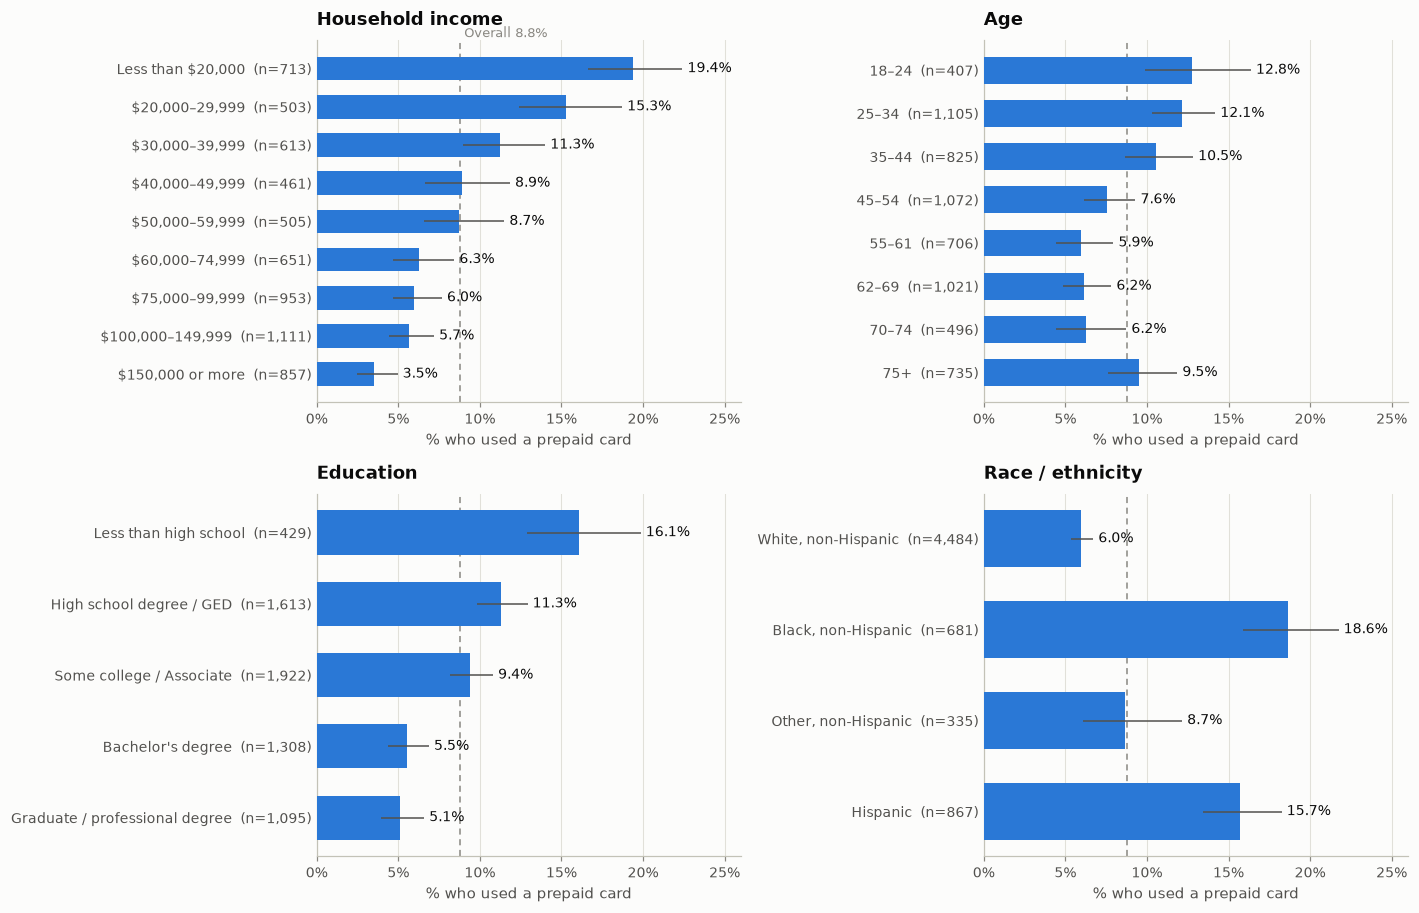

In [22]:
demo = rate_panel([("PPINCIMP", "Household income"), ("agecat", "Age"),
                   ("PPEDUC", "Education"), ("PPETHM", "Race / ethnicity")],
                  ncols=2, figsize=(13, 8.4), filename="02_demographics_core.png")

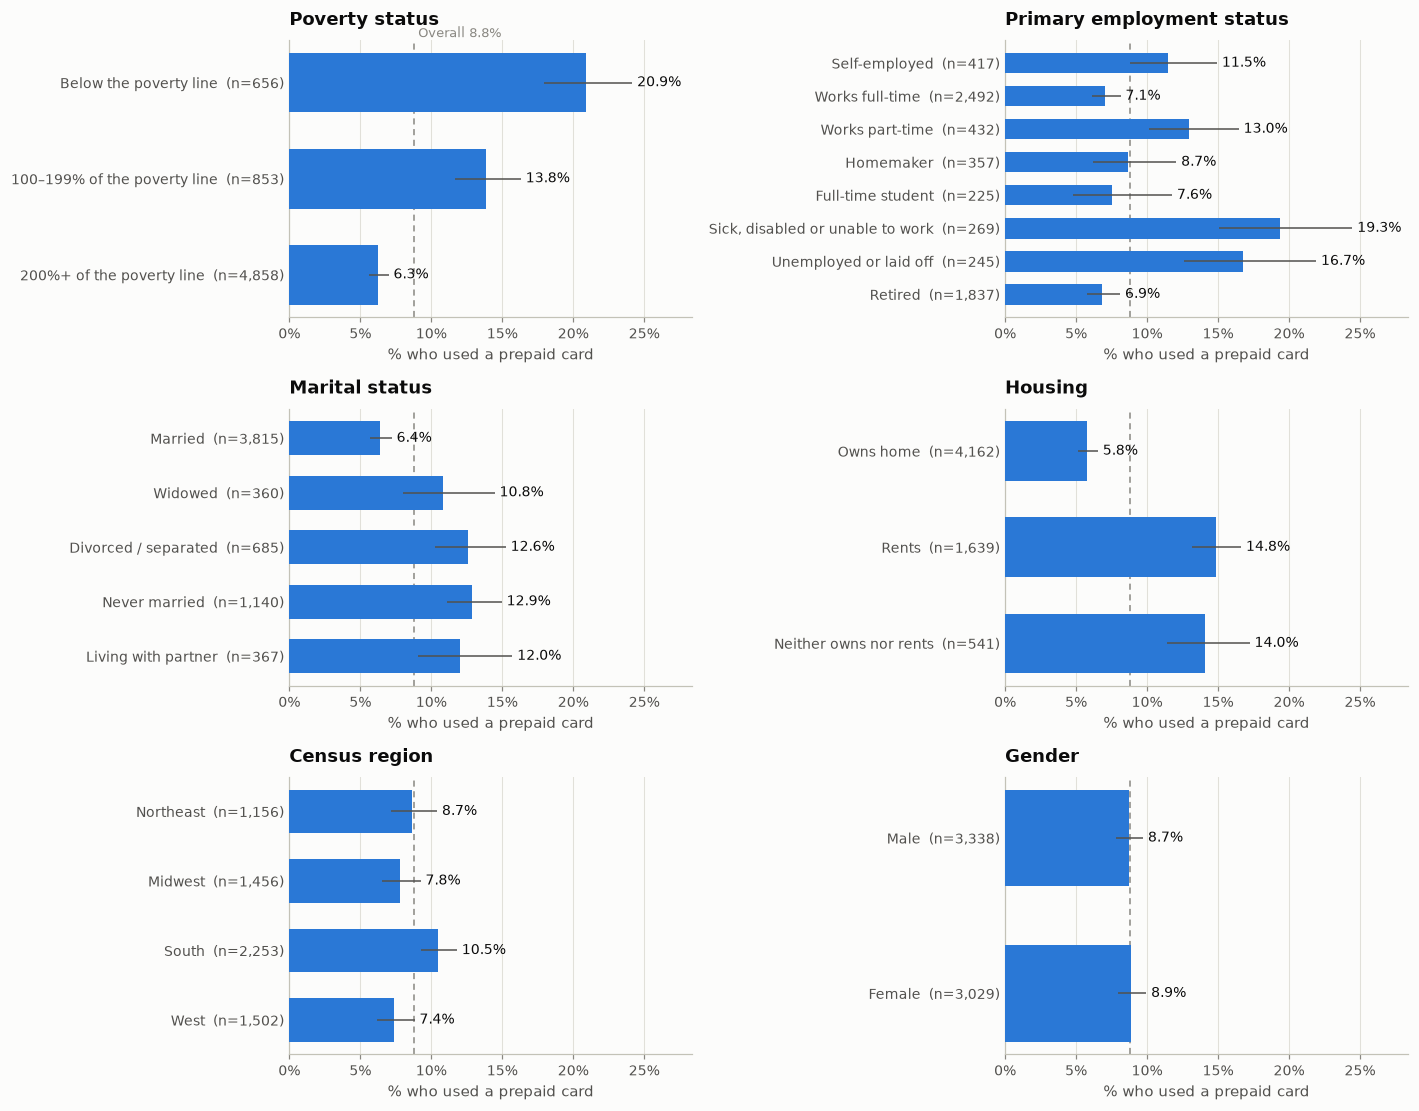

In [23]:
demo2 = rate_panel([("fpl", "Poverty status"), ("EMPLOY", "Primary employment status"),
                    ("PPMARIT", "Marital status"), ("HOUSING", "Housing"),
                    ("PPREG4", "Census region"), ("PPGENDER", "Gender")],
                   ncols=2, figsize=(13, 10.2), filename="03_demographics_other.png")

**Takeaways**

- **Income is the clearest demographic gradient.** Use falls steadily from 19.4% in households under \$20,000 to 3.5% at \$150,000 or more. People below the poverty line use prepaid cards at 20.9%, against 6.3% for those at twice the poverty line or above.
- **Age:** use is highest under 35 (12–13%) and lowest between 55 and 74 (about 6%), with a small rise at 75+ (9.5%).
- **Education:** 16.1% without a high-school diploma, falling to 5.1% with a graduate degree.
- **Race / ethnicity:** 18.6% of Black and 15.7% of Hispanic respondents, against 6.0% of White respondents.
- **Work and housing:** highest among people unable to work through sickness or disability (19.3%), the unemployed (16.7%) and part-time workers (13.0%); renters (14.8%) use prepaid cards far more than homeowners (5.8%).
- **No difference by gender** (8.7% vs 8.9%) and only a small one by region (South 10.5%, West 7.4%).

**Flag for Step 5.** Race/ethnicity carries signal, but using it to select who receives a credit-related marketing offer raises fair-lending concerns. It is clearly relevant to the CFPB's at-risk analysis. Whether it enters the card company's targeting model is a decision for the team, not a statistical one.

### 4.2 Banking relationship and products held

For each product, the chart compares the prepaid usage rate of people who hold the product with those who do not. A wide gap means the product separates users from non-users well.

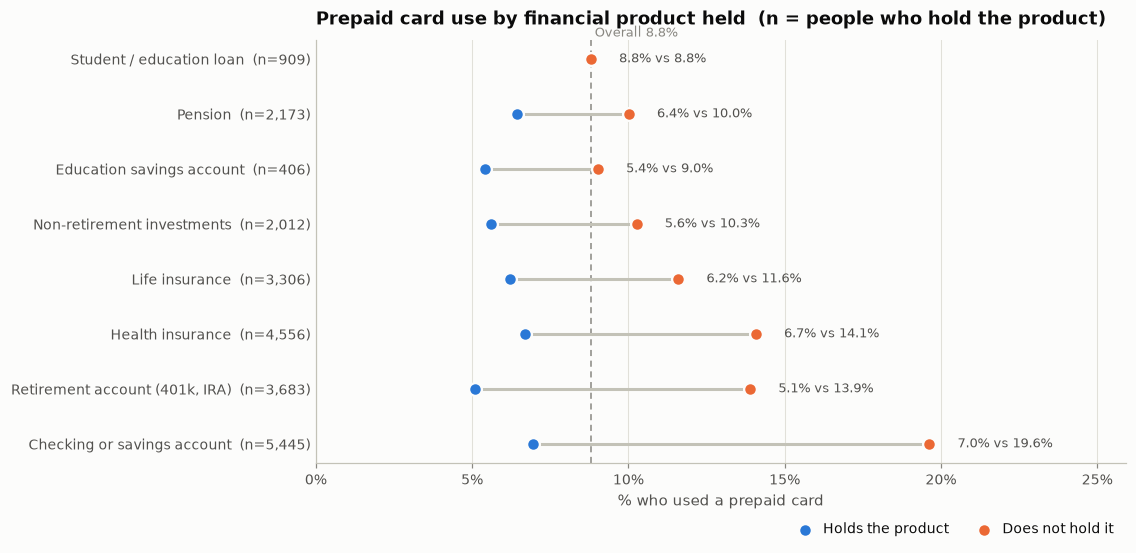

,label,rate_yes,rate_no,ratio_yes_vs_no
0,Student / education loan,8.8%,8.8%,1.00x
1,Pension,6.4%,10.0%,0.64x
2,Education savings account,5.4%,9.0%,0.60x
3,Non-retirement investments,5.6%,10.3%,0.55x
4,Life insurance,6.2%,11.6%,0.53x
5,Health insurance,6.7%,14.1%,0.48x
6,"Retirement account (401k, IRA)",5.1%,13.9%,0.37x
7,Checking or savings account,7.0%,19.6%,0.35x


In [24]:
def binary_contrast(data, cols, names=None):
    """Usage rate when a 0/1 indicator is 1 versus 0, with group sizes and the ratio between them."""
    out = []
    for col in cols:
        g = data.groupby(col)[TARGET].agg(["size", "mean"])
        out.append({"variable": col, "label": (names or {}).get(col, codebook.loc[col, "codebook_label"] if col in codebook.index else col),
                    "rate_yes": g.loc[1, "mean"], "n_yes": int(g.loc[1, "size"]),
                    "rate_no": g.loc[0, "mean"], "n_no": int(g.loc[0, "size"])})
    t = pd.DataFrame(out).set_index("variable")
    t["ratio_yes_vs_no"] = t["rate_yes"] / t["rate_no"]
    return t


def plot_contrast(t, title, filename, yes_label, no_label, figsize=(9.5, 5)):
    t = t.sort_values("ratio_yes_vs_no")
    y = np.arange(len(t))
    fig, ax = plt.subplots(figsize=figsize)
    ax.hlines(y, t["rate_no"] * 100, t["rate_yes"] * 100, color=AXIS, linewidth=2, zorder=2)
    ax.scatter(t["rate_yes"] * 100, y, s=70, color=BLUE, zorder=3, label=yes_label, edgecolor=SURFACE, linewidth=1.5)
    ax.scatter(t["rate_no"] * 100, y, s=70, color=ORANGE, zorder=3, label=no_label, edgecolor=SURFACE, linewidth=1.5)
    ax.axvline(BASE * 100, color=MUTED, linewidth=1, linestyle=(0, (4, 3)), zorder=1)
    ax.text(BASE * 100, 1.0, f" Overall {BASE:.1%}", transform=ax.get_xaxis_transform(), fontsize=8.5, color=MUTED, va="bottom")
    for yi, (_, r) in zip(y, t.iterrows()):
        right = max(r["rate_yes"], r["rate_no"]) * 100
        ax.text(right + 0.9, yi, f"{r['rate_yes']:.1%} vs {r['rate_no']:.1%}", va="center", fontsize=8.5, color=INK2)
    ax.set_yticks(y, [f"{lab}  (n={n:,})" for lab, n in zip(t["label"], t["n_yes"])])
    ax.set_xlim(0, max(t["rate_yes"].max(), t["rate_no"].max()) * 100 * 1.32)
    ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(decimals=0))
    ax.set_xlabel("% who used a prepaid card")
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0)
    ax.set_title(title)
    ax.legend(loc="upper right", bbox_to_anchor=(1.0, -0.11), ncol=2, columnspacing=1.6, handletextpad=0.3)
    fig.savefig(FIG_DIR / filename)
    plt.show()
    return t


product_names = {"PRODHAVE_1": "Checking or savings account", "PRODHAVE_2": "Life insurance", "PRODHAVE_3": "Health insurance",
                 "PRODHAVE_4": "Retirement account (401k, IRA)", "PRODHAVE_5": "Pension", "PRODHAVE_6": "Non-retirement investments",
                 "PRODHAVE_7": "Education savings account", "PRODHAVE_8": "Student / education loan"}
products = plot_contrast(binary_contrast(clean, list(product_names), product_names),
                         "Prepaid card use by financial product held  (n = people who hold the product)",
                         "04_products_held.png", "Holds the product", "Does not hold it")
fmt(products[["label", "rate_yes", "rate_no", "ratio_yes_vs_no"]].iloc[::-1],
    {"rate_yes": "{:.1%}", "rate_no": "{:.1%}", "ratio_yes_vs_no": "{:.2f}x"}, hide_index=True)

**Takeaways**

- **Bank-account status is the sharpest single divide among products:** 19.6% of people who report no checking or savings account use a prepaid card, against 7.0% of those with one (2.8 times higher).
- **Holding long-term financial products goes with lower use:** retirement account 5.1% vs 13.9%, health insurance 6.7% vs 14.1%, life insurance 6.2% vs 11.6%.
- **Student loans make no difference** (8.8% either way).
- **Prepaid cards are not only a substitute for a bank account.** 68% of prepaid users do have a checking or savings account.

**Caveat.** "No account" means the respondent did not tick the box (14.5% of the sample). That is higher than typical estimates of the unbanked population, so some of these people may simply have skipped the item. It is described here as "no account reported".

### 4.3 Financial fragility

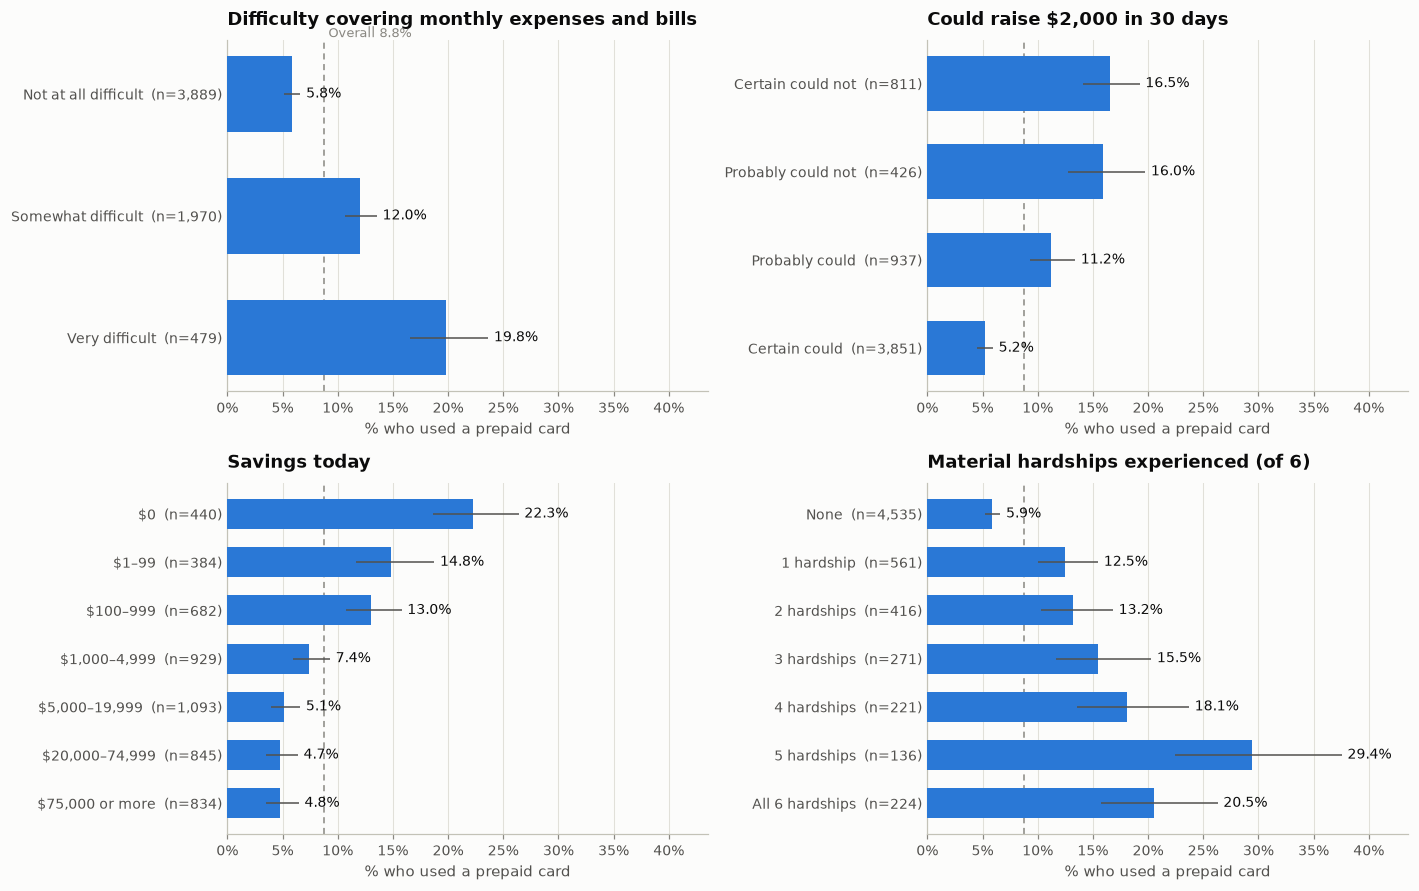

In [25]:
fragility = rate_panel([("ENDSMEET", "Difficulty covering monthly expenses and bills"),
                        ("ABSORBSHOCK", "Could raise $2,000 in 30 days"),
                        ("SAVINGSRANGES", "Savings today"),
                        ("HARDSHIP_COUNT", "Material hardships experienced (of 6)")],
                       ncols=2, figsize=(13, 8.2), filename="05_financial_fragility.png")

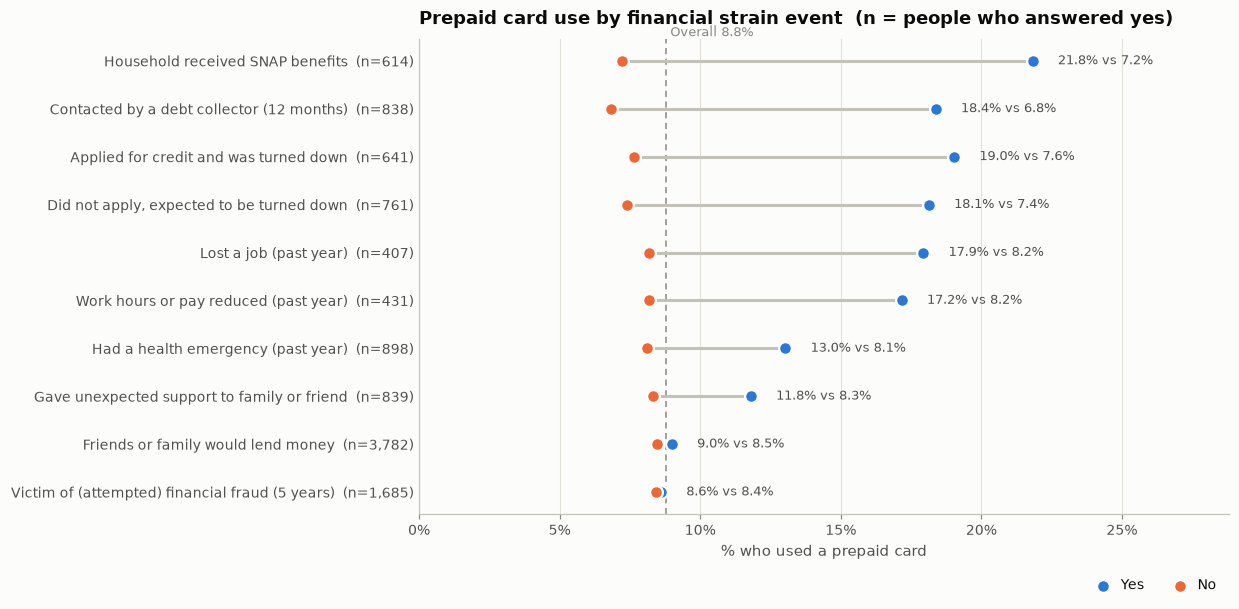

In [26]:
strain_names = {"SNAP": "Household received SNAP benefits", "COLLECT": "Contacted by a debt collector (12 months)",
                "REJECTED_1": "Applied for credit and was turned down", "REJECTED_2": "Did not apply, expected to be turned down",
                "SHOCKS_1": "Lost a job (past year)", "SHOCKS_2": "Work hours or pay reduced (past year)",
                "SHOCKS_5": "Had a health emergency (past year)", "SHOCKS_11": "Gave unexpected support to family or friend",
                "BORROW_1": "Friends or family would lend money", "FRAUD2": "Victim of (attempted) financial fraud (5 years)"}
strain = plot_contrast(binary_contrast(clean, list(strain_names), strain_names),
                       "Prepaid card use by financial strain event  (n = people who answered yes)",
                       "06_strain_events.png", "Yes", "No", figsize=(9.5, 5.6))

**Takeaways**

- **Every measure of financial strain points the same way.**
  - Covering monthly bills: 5.8% (not at all difficult) → 12.0% → 19.8% (very difficult).
  - Raising \$2,000 in 30 days: 16.5% of those certain they could not, against 5.2% of those certain they could.
  - Savings: 22.3% with \$0, falling to about 5% from \$5,000 upwards.
  - Material hardships: 5.9% with none, rising to 29.4% with five (the two highest groups are small, so their intervals are wide).
- **Strain events roughly double to triple the rate:** SNAP benefits 21.8% vs 7.2%; contacted by a debt collector 18.4% vs 6.8%; turned down for credit 19.0% vs 7.6%; did not apply for credit expecting refusal 18.1% vs 7.4%; lost a job 17.9% vs 8.2%.
- **Two things make no difference:** having been a victim of financial fraud, and having friends or family who would lend money.

### 4.4 Financial well-being, skill and knowledge scores

Three of the four summary scores are split into five bands of roughly equal size (lowest fifth to highest fifth). `LMscore` has only four possible values and is shown as is.

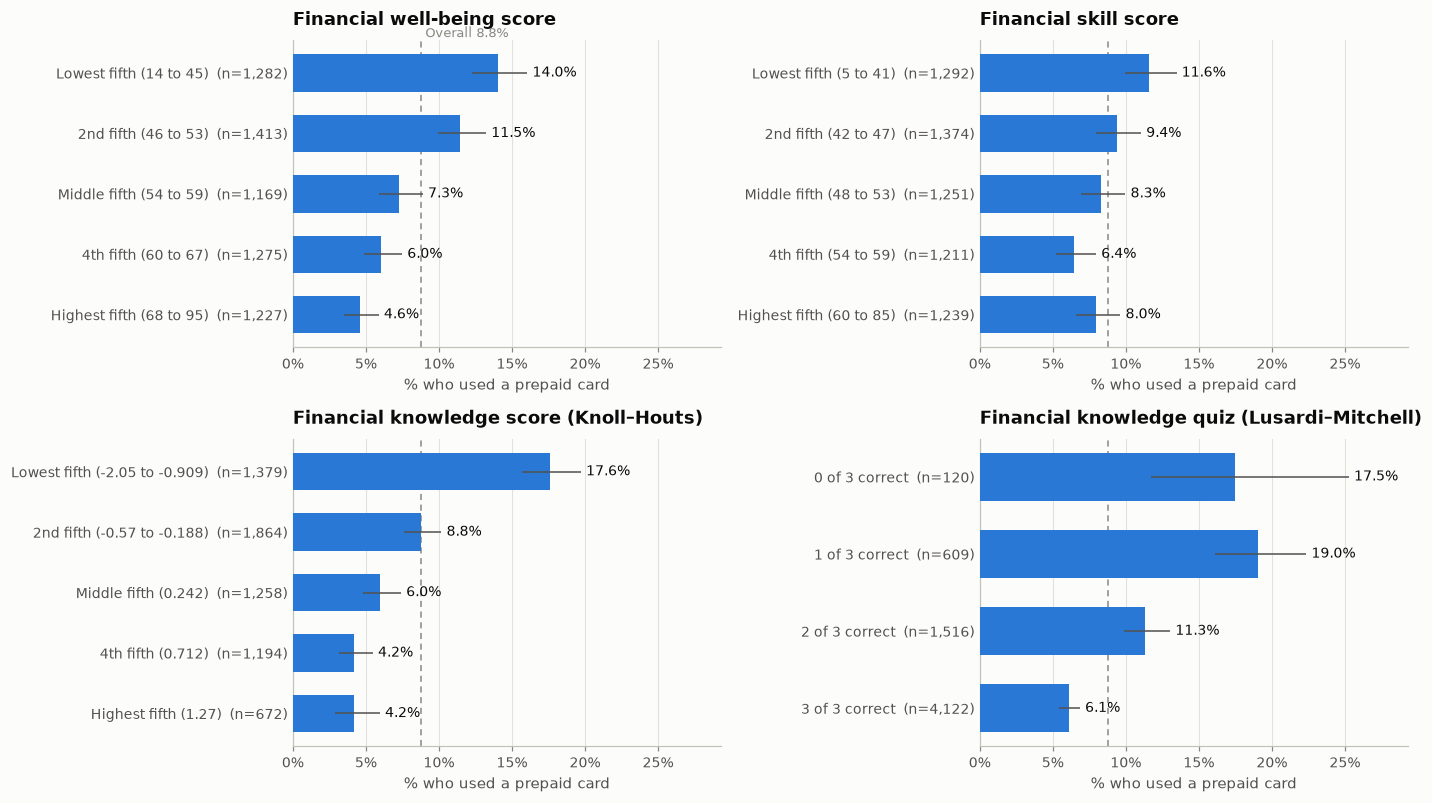

,Non-users (mean),Users (mean),Gap in standard deviations
FWBscore,56.60,50.78,-0.41
FSscore,50.96,48.90,-0.16
KHscore,-0.01,-0.49,-0.60
LMscore,2.55,2.17,-0.51


In [27]:
def score_bands(col, q=5):
    """Label each respondent with the quintile band of a score, e.g. 'Lowest fifth (14–45)'."""
    s = clean[col]
    codes = pd.qcut(s, q, labels=False, duplicates="drop")
    names = ["Lowest fifth", "2nd fifth", "Middle fifth", "4th fifth", "Highest fifth"]
    bounds = s.groupby(codes).agg(["min", "max"])
    if len(bounds) != q:
        names = [f"Band {i + 1}" for i in range(len(bounds))]
    span = {k: (f"{lo_:.3g}" if lo_ == hi_ else f"{lo_:.3g} to {hi_:.3g}") for k, (lo_, hi_) in bounds.iterrows()}
    label = {k: f"{names[i]} ({span[k]})" for i, k in enumerate(bounds.index)}
    return codes.map(label), list(label.values())


score_specs = [("FWBscore", "Financial well-being score"), ("FSscore", "Financial skill score"),
               ("KHscore", "Financial knowledge score (Knoll–Houts)"), ("LMscore", "Financial knowledge quiz (Lusardi–Mitchell)")]
score_tables = {}
for col, _ in score_specs:
    if col == "LMscore":
        score_tables[col] = rate_table(clean, col)
    else:
        band, order = score_bands(col)
        score_tables[col] = rate_table(clean.assign(_band=band), "_band").loc[order]

xmax = max(t["hi"].max() for t in score_tables.values()) * 100 * 1.16
fig, axes = plt.subplots(2, 2, figsize=(13, 7.4))
for ax, (col, title) in zip(axes.ravel(), score_specs):
    plot_rates(ax, score_tables[col], title, xmax)
axes[0, 0].text(BASE * 100, 1.0, f" Overall {BASE:.1%}", transform=axes[0, 0].get_xaxis_transform(), fontsize=8.5, color=MUTED, va="bottom")
fig.tight_layout()
fig.savefig(FIG_DIR / "07_scores.png")
plt.show()

score_compare = clean.groupby(TARGET)[["FWBscore", "FSscore", "KHscore", "LMscore"]].mean().T
score_compare.columns = ["Non-users (mean)", "Users (mean)"]
score_compare["Gap in standard deviations"] = (score_compare["Users (mean)"] - score_compare["Non-users (mean)"]) / clean[score_compare.index].std()
fmt(score_compare, "{:.2f}")

**Takeaways**

- **Tested financial knowledge separates users best.** 17.6% in the lowest knowledge band against 4.2% in the top two; on the three-question quiz, 17.5–19.0% of those with zero or one correct against 6.1% of those with all three. Users score 0.60 standard deviations lower on the knowledge score.
- **Financial well-being also separates them:** 14.0% in the lowest fifth against 4.6% in the highest (users are 0.41 standard deviations lower).
- **Self-assessed financial skill barely does:** 11.6% vs 8.0%, a gap of only 0.16 standard deviations.
- **The contrast matters for the CFPB question.** Prepaid users know measurably less about financial products than non-users, but rate their own financial skills almost as highly. That gap between knowledge and confidence is a marker of the "unsophisticated user" concern raised in the brief.

Note: the knowledge score has only 11 possible values, so its five bands are unequal in size.

### 4.5 Overlap with other alternative financial services

These are the "restricted" same-question items (Section 3.3). They are shown to describe users, not as proposed predictors.

In [28]:
afs_names = {"PRODUSE_1": "Payday or cash-advance loan", "PRODUSE_2": "Pawn or auto-title loan",
             "PRODUSE_4": "Non-bank international money transfer", "PRODUSE_5": "Non-bank cheque cashing or money order"}
overlap = pd.DataFrame({
    "Among prepaid users": clean.loc[clean[TARGET] == 1, list(afs_names)].mean(),
    "Among non-users": clean.loc[clean[TARGET] == 0, list(afs_names)].mean(),
})
overlap.loc["Any of the four"] = [clean.loc[clean[TARGET] == 1, list(afs_names)].max(axis=1).mean(),
                                  clean.loc[clean[TARGET] == 0, list(afs_names)].max(axis=1).mean()]
overlap["Ratio"] = overlap["Among prepaid users"] / overlap["Among non-users"]
overlap.index = [afs_names.get(i, i) for i in overlap.index]
fmt(overlap, {"Among prepaid users": "{:.1%}", "Among non-users": "{:.1%}", "Ratio": "{:.1f}x"})

,Among prepaid users,Among non-users,Ratio
Payday or cash-advance loan,5.0%,2.5%,2.0x
Pawn or auto-title loan,4.6%,1.5%,3.1x
Non-bank international money transfer,6.1%,4.1%,1.5x
Non-bank cheque cashing or money order,13.6%,5.9%,2.3x
Any of the four,21.2%,12.7%,1.7x


**Takeaways**

- Prepaid users are more likely to use every other alternative financial service: pawn or auto-title loans 3.1 times, cheque cashing or money orders 2.3 times, payday loans 2.0 times.
- 21.2% of prepaid users used at least one of the four, against 12.7% of non-users. Put the other way, **about four in five prepaid users use none of them**, so prepaid use is not simply one symptom of heavy reliance on fringe finance.
- These items stay "restricted". The recommendation is to leave them out of the predictive model and use them to describe risk in the CFPB analysis.

### 4.6 Which variables carry the most signal?

Every candidate predictor is scored on the strength of its association with prepaid use, so that variables of different types can be ranked on one scale.

- **Measure:** bias-corrected Cramér's V (0 = no association, 1 = perfect). Continuous scores are split into fifths first. It works for unordered categories, ordered scales and yes/no variables alike.
- **Significance:** chi-square test, with the Benjamini–Hochberg correction because many variables are tested at once (5% false-discovery rate).
- **Direction:** for ordered variables, the sign of the rank correlation with prepaid use.

This is a screening tool. It looks at one variable at a time and cannot see overlap between variables; that is addressed in 4.7.

Candidate predictors screened: 178
Significantly associated with prepaid use (5% false-discovery rate): 141


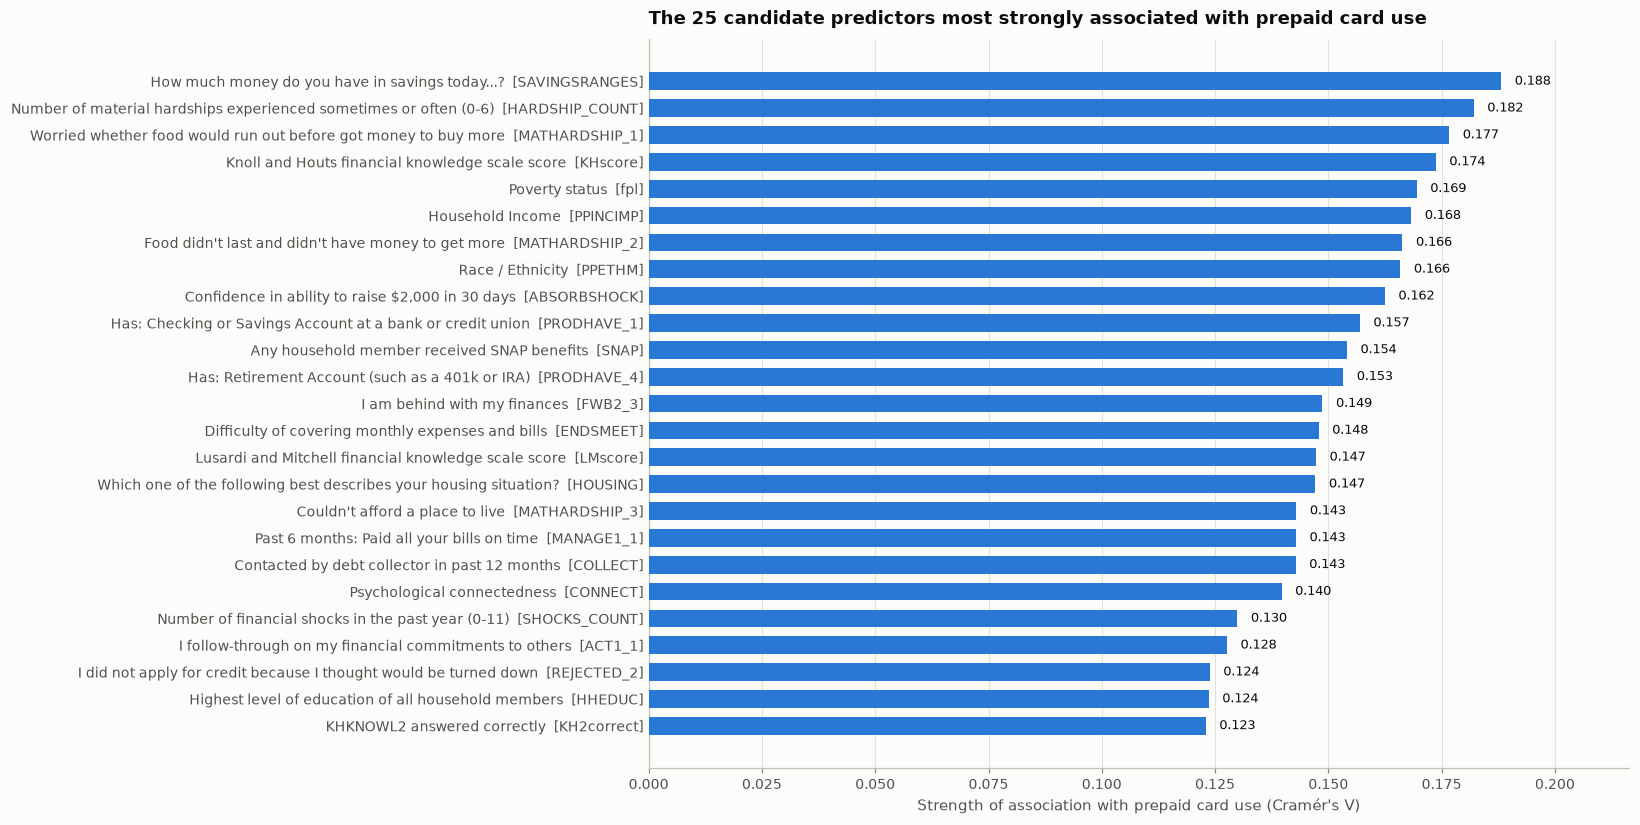

In [29]:
def cramers_v(x, y):
    """Bias-corrected Cramér's V and chi-square p-value for two categorical series."""
    ct = pd.crosstab(x, y)
    chi2, p, _, _ = stats.chi2_contingency(ct, correction=False)
    n = ct.to_numpy().sum()
    r, k = ct.shape
    phi2 = max(0.0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    r_c, k_c = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / min(k_c - 1, r_c - 1)), p


def association_table(data, cols):
    out = []
    for col in cols:
        s = data[col]
        mtype = roles.loc[col, "measurement_type"]
        levels = pd.qcut(s, 5, labels=False, duplicates="drop") if mtype == "Continuous score" else s
        ok = levels.notna()
        v, p = cramers_v(levels[ok], data.loc[ok, TARGET])
        level_rates = data.loc[ok].groupby(levels[ok])[TARGET].agg(["mean", "size"])
        level_rates = level_rates[level_rates["size"] >= 50]
        if mtype.startswith("Nominal"):
            direction = "n/a (unordered)"
        else:
            rho = stats.spearmanr(s[ok], data.loc[ok, TARGET])[0]
            direction = "Higher value, more use" if rho > 0 else "Higher value, less use"
        out.append({"variable": col, "cramers_v": v, "p_value": p, "direction": direction,
                    "lowest_group_rate": level_rates["mean"].min(), "highest_group_rate": level_rates["mean"].max()})
    t = pd.DataFrame(out).set_index("variable")
    t["significant_fdr_5pct"] = stats.false_discovery_control(t["p_value"], method="bh") < 0.05
    return t.sort_values("cramers_v", ascending=False)


assoc = association_table(clean, CANDIDATES).join(roles[["label", "group", "measurement_type"]])
print(f"Candidate predictors screened: {len(assoc)}")
print(f"Significantly associated with prepaid use (5% false-discovery rate): {int(assoc['significant_fdr_5pct'].sum())}")

TOP_N = 25
top = assoc.head(TOP_N).iloc[::-1]
fig, ax = plt.subplots(figsize=(11.5, 8.6))
ax.barh(np.arange(len(top)), top["cramers_v"], height=0.66, color=BLUE, zorder=3)
for i, v in enumerate(top["cramers_v"]):
    ax.text(v + 0.003, i, f"{v:.3f}", va="center", fontsize=8.5, color=INK)
ax.set_yticks(np.arange(len(top)), [f"{lab if len(lab) <= 74 else lab[:72] + chr(8230)}  [{var}]" for var, lab in zip(top.index, top["label"])])
ax.set_xlim(0, top["cramers_v"].max() * 1.15)
ax.set_xlabel("Strength of association with prepaid card use (Cramér's V)")
ax.set_title(f"The {TOP_N} candidate predictors most strongly associated with prepaid card use")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
fig.savefig(FIG_DIR / "08_association_ranking.png")
plt.show()

In [30]:
show = assoc.head(TOP_N)[["label", "group", "cramers_v", "direction", "lowest_group_rate", "highest_group_rate"]]
display(fmt(show, {"cramers_v": "{:.3f}", "lowest_group_rate": "{:.1%}", "highest_group_rate": "{:.1%}"}))

group_signal = assoc.groupby("group").agg(candidates=("cramers_v", "size"), significant=("significant_fdr_5pct", "sum"),
                                          strongest=("cramers_v", "max"), median=("cramers_v", "median"))
group_signal["strongest_variable"] = assoc.groupby("group")["cramers_v"].idxmax()
display(fmt(group_signal.sort_values("strongest", ascending=False), {"strongest": "{:.3f}", "median": "{:.3f}"}))

nr_flags = assoc.loc[[c for c in assoc.index if c.endswith("_NR")], ["label", "cramers_v", "p_value", "significant_fdr_5pct"]]
nr_rates = binary_contrast(clean, nr_flags.index.tolist())[["rate_yes", "rate_no"]].rename(
    columns={"rate_yes": "usage if non-response", "rate_no": "usage if answered"})
display(fmt(nr_flags.join(nr_rates), {"cramers_v": "{:.3f}", "p_value": "{:.4f}",
                                      "usage if non-response": "{:.1%}", "usage if answered": "{:.1%}"}))

,label,group,cramers_v,direction,lowest_group_rate,highest_group_rate
variable,,,,,,
SAVINGSRANGES,How much money do you have in savings today...?,"Housing, savings and household resources",0.188,"Higher value, less use",4.7%,22.3%
HARDSHIP_COUNT,Number of material hardships experienced sometimes or often (0-6),"Financial strain, hardship and shocks",0.182,"Higher value, more use",5.9%,29.4%
MATHARDSHIP_1,Worried whether food would run out before got money to buy more,"Financial strain, hardship and shocks",0.177,"Higher value, more use",6.5%,22.1%
KHscore,Knoll and Houts financial knowledge scale score,Financial knowledge and numeracy (tested),0.174,"Higher value, less use",4.2%,17.6%
fpl,Poverty status,Demographics and geography,0.169,"Higher value, less use",6.3%,20.9%
PPINCIMP,Household Income,Demographics and geography,0.168,"Higher value, less use",3.5%,19.4%
MATHARDSHIP_2,Food didn't last and didn't have money to get more,"Financial strain, hardship and shocks",0.166,"Higher value, more use",6.8%,21.2%
PPETHM,Race / Ethnicity,Demographics and geography,0.166,n/a (unordered),6.0%,18.6%
ABSORBSHOCK,"Confidence in ability to raise $2,000 in 30 days","Financial strain, hardship and shocks",0.162,"Higher value, less use",5.2%,16.5%


,candidates,significant,strongest,median,strongest_variable
group,,,,,
"Housing, savings and household resources",13,11,0.188,0.085,SAVINGSRANGES
"Financial strain, hardship and shocks",34,27,0.182,0.081,HARDSHIP_COUNT
Financial knowledge and numeracy (tested),16,16,0.174,0.097,KHscore
Demographics and geography,22,12,0.169,0.035,fpl
Financial products held,8,7,0.157,0.085,PRODHAVE_1
Financial well-being,14,14,0.149,0.086,FWB2_3
Money management behaviour,29,24,0.143,0.048,MANAGE1_1
"Attitudes, traits and health",14,11,0.140,0.051,CONNECT
"Employment, retirement and military",2,1,0.114,0.061,EMPLOY


,label,cramers_v,p_value,significant_fdr_5pct,usage if non-response,usage if answered
variable,,,,,,
ABSORBSHOCK_NR,"Non-response flag: Confidence in ability to raise $2,000 in 30 days",0.055,0.0000,True,15.5%,8.4%
HSLOC_NR,Non-response flag: Where did you live at age 17?,0.054,0.0000,True,13.4%,8.3%
FRAUD2_NR,Non-response flag: Victim of financial fraud or attempted financial fraud in past 5 years,0.034,0.0039,True,12.2%,8.5%
KIDS_NoChildren_NR,Non-response flag: I have no children that I support financially,0.020,0.0634,False,6.7%,9.0%
SAVINGSRANGES_NR,Non-response flag: How much money do you have in savings today...?,0.003,0.3036,False,9.6%,8.6%
HOUSERANGES_NR,Non-response flag: About how much do you pay for your home each month?,0.000,0.9696,False,8.8%,8.8%


**Takeaways**

- **Signal is broad but individually modest.** 141 of 178 candidates are reliably associated with prepaid use, yet the strongest reaches only 0.19 on a 0–1 scale. No single question identifies users; a model has to combine many.
- **The top of the ranking is one story told several ways:** little savings, material hardship, low income and poverty, low financial knowledge, and no bank account.
- **Almost every theme contributes.** Resources, strain, knowledge, demographics, products and well-being each have a variable at 0.15 or above. The weakest themes are upbringing (4 of 10 variables significant, best 0.06) and self-assessed skill (best 0.10).
- **Non-response is informative for some questions only.** People who did not know whether they could raise \$2,000 use prepaid cards at 15.5% (8.4% among those who answered), and non-response on childhood location and on fraud also carries some signal. Declining to state savings or housing cost carries none (9.6% vs 8.6%, and 8.8% vs 8.8%), so those gaps can be imputed without a flag.

### 4.7 Overlap between the strongest variables

Many of the top-ranked variables measure the same underlying thing. Putting several near-duplicates into a 20-variable model wastes slots and makes the model harder to interpret. The heatmap shows the rank correlation between the strongest ordered variables.

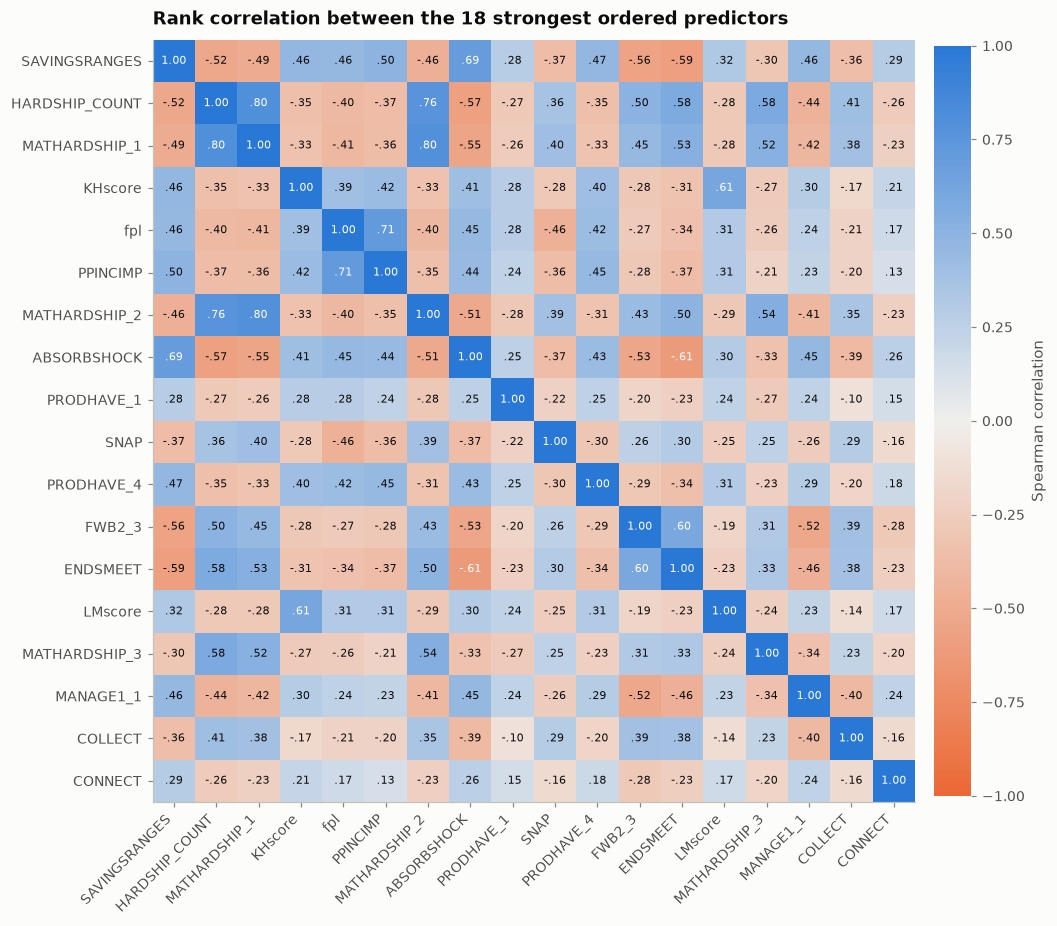

,variable_a,variable_b,spearman,a_label,b_label
0,HARDSHIP_COUNT,MATHARDSHIP_1,0.80,Number of material hardships experienced sometimes,Worried whether food would run out before got mone
1,MATHARDSHIP_1,MATHARDSHIP_2,0.80,Worried whether food would run out before got mone,Food didn't last and didn't have money to get more
2,HARDSHIP_COUNT,MATHARDSHIP_2,0.76,Number of material hardships experienced sometimes,Food didn't last and didn't have money to get more
3,fpl,PPINCIMP,0.71,Poverty status,Household Income
4,SAVINGSRANGES,ABSORBSHOCK,0.69,How much money do you have in savings today...?,"Confidence in ability to raise $2,000 in 30 days"
5,ABSORBSHOCK,ENDSMEET,-0.61,"Confidence in ability to raise $2,000 in 30 days",Difficulty of covering monthly expenses and bills
6,KHscore,LMscore,0.61,Knoll and Houts financial knowledge scale score,Lusardi and Mitchell financial knowledge scale sco
7,FWB2_3,ENDSMEET,0.60,I am behind with my finances,Difficulty of covering monthly expenses and bills
8,SAVINGSRANGES,ENDSMEET,-0.59,How much money do you have in savings today...?,Difficulty of covering monthly expenses and bills
9,HARDSHIP_COUNT,MATHARDSHIP_3,0.58,Number of material hardships experienced sometimes,Couldn't afford a place to live


In [31]:
ordered_top = [v for v in assoc.index if not assoc.loc[v, "measurement_type"].startswith("Nominal") and not v.endswith("_NR")][:18]
corr = clean[ordered_top].corr(method="spearman")

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, cmap=DIV_CMAP, vmin=-1, vmax=1)
ax.set_xticks(range(len(ordered_top)), ordered_top, rotation=45, ha="right")
ax.set_yticks(range(len(ordered_top)), ordered_top)
for i in range(len(ordered_top)):
    for j in range(len(ordered_top)):
        val = corr.iloc[i, j]
        ax.text(j, i, f"{val:.2f}".replace("0.", ".").replace("-.", "-."), ha="center", va="center", fontsize=7.5,
                color="white" if abs(val) > 0.6 else INK)
ax.grid(visible=False)
ax.set_title("Rank correlation between the 18 strongest ordered predictors")
cbar = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
cbar.set_label("Spearman correlation")
cbar.outline.set_visible(False)
fig.savefig(FIG_DIR / "09_correlation_heatmap.png")
plt.show()

pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().rename("spearman").reset_index()
         .rename(columns={"level_0": "variable_a", "level_1": "variable_b"}))
pairs = pairs.reindex(pairs["spearman"].abs().sort_values(ascending=False).index).head(10)
pairs["a_label"] = pairs["variable_a"].map(roles["label"]).str[:50]
pairs["b_label"] = pairs["variable_b"].map(roles["label"]).str[:50]
fmt(pairs, {"spearman": "{:.2f}"}, hide_index=True)

**Takeaways**

- **The strongest variables form a few tight clusters**, each measuring one thing:
  - *Food and material hardship:* `MATHARDSHIP_1`, `MATHARDSHIP_2` and `HARDSHIP_COUNT` (correlations 0.76–0.80).
  - *Income:* `PPINCIMP` and `fpl` (0.71).
  - *Liquidity:* `SAVINGSRANGES`, `ABSORBSHOCK`, `ENDSMEET` and `FWB2_3` (0.5–0.7 in size).
  - *Knowledge:* `KHscore` and `LMscore` (0.61).
- **Implication for the 20-variable limit:** take one representative per cluster (for example `HARDSHIP_COUNT` in place of six hardship items, one of income or poverty status, one knowledge score) and spend the remaining slots on themes that add something different.
- **Bank-account status is the most independent strong signal:** `PRODHAVE_1` correlates at no more than 0.28 with any other top variable, so it adds information the others do not.

### 4.8 Do the effects combine, and are they robust?

**Income and banking status together.** If low income and lacking a bank account were the same signal, usage would not differ by account status within an income band.

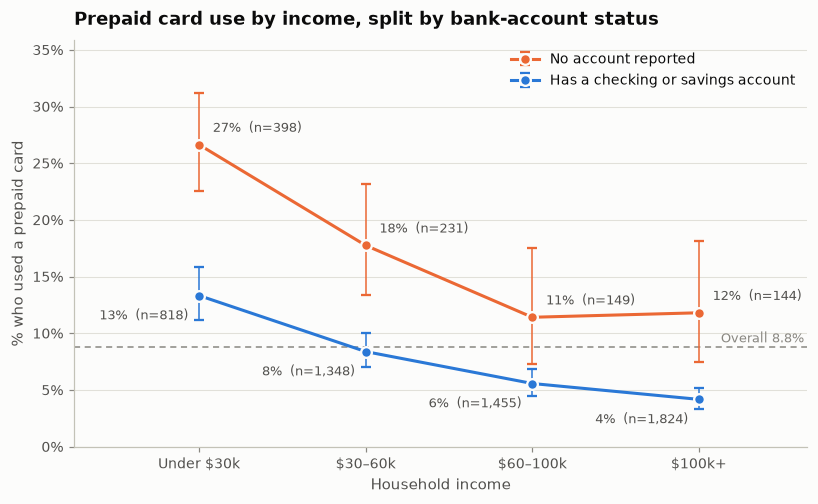

In [32]:
INCOME_BANDS = {1: "Under $30k", 2: "Under $30k", 3: "$30–60k", 4: "$30–60k", 5: "$30–60k",
                6: "$60–100k", 7: "$60–100k", 8: "$100k+", 9: "$100k+"}
INCOME_ORDER = ["Under $30k", "$30–60k", "$60–100k", "$100k+"]
AGE_BANDS = {1: "18–34", 2: "18–34", 3: "35–54", 4: "35–54", 5: "55–69", 6: "55–69", 7: "70+", 8: "70+"}
AGE_ORDER = ["18–34", "35–54", "55–69", "70+"]
view = clean.assign(income_band=clean["PPINCIMP"].map(INCOME_BANDS), age_band=clean["agecat"].map(AGE_BANDS),
                    account=clean["PRODHAVE_1"].map({1: "Has a checking or savings account", 0: "No account reported"}))

inc_acct = view.groupby(["account", "income_band"])[TARGET].agg(n="size", users="sum").reset_index()
inc_acct["rate"] = inc_acct["users"] / inc_acct["n"]
inc_acct["lo"], inc_acct["hi"] = wilson_interval(inc_acct["users"], inc_acct["n"])

fig, ax = plt.subplots(figsize=(8.6, 4.8))
x = np.arange(len(INCOME_ORDER))
for name, color in [("No account reported", ORANGE), ("Has a checking or savings account", BLUE)]:
    d = inc_acct[inc_acct["account"] == name].set_index("income_band").loc[INCOME_ORDER]
    ax.errorbar(x, d["rate"] * 100, yerr=[(d["rate"] - d["lo"]) * 100, (d["hi"] - d["rate"]) * 100],
                color=color, linewidth=2, marker="o", markersize=7, markeredgecolor=SURFACE, markeredgewidth=1.5,
                elinewidth=1, capsize=3, label=name, zorder=3)
    for xi, (rate, n) in enumerate(zip(d["rate"], d["n"])):
        above = name.startswith("No")
        ax.annotate(f"{rate:.0%}  (n={n:,})", (xi, rate * 100), textcoords="offset points",
                    xytext=(9, 11) if above else (-7, -13), ha="left" if above else "right", va="center",
                    fontsize=8.5, color=INK2)
ax.axhline(BASE * 100, color=MUTED, linewidth=1, linestyle=(0, (4, 3)))
ax.text(len(INCOME_ORDER) - 0.37, BASE * 100 + 0.4, f"Overall {BASE:.1%}", fontsize=8.5, color=MUTED, ha="right")
ax.set_xticks(x, INCOME_ORDER)
ax.set_xlim(-0.75, len(INCOME_ORDER) - 0.35)
ax.set_ylim(0, inc_acct["hi"].max() * 100 * 1.15)
ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(decimals=0))
ax.set_xlabel("Household income")
ax.set_ylabel("% who used a prepaid card")
ax.set_title("Prepaid card use by income, split by bank-account status")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right")
fig.savefig(FIG_DIR / "10_income_by_account.png")
plt.show()

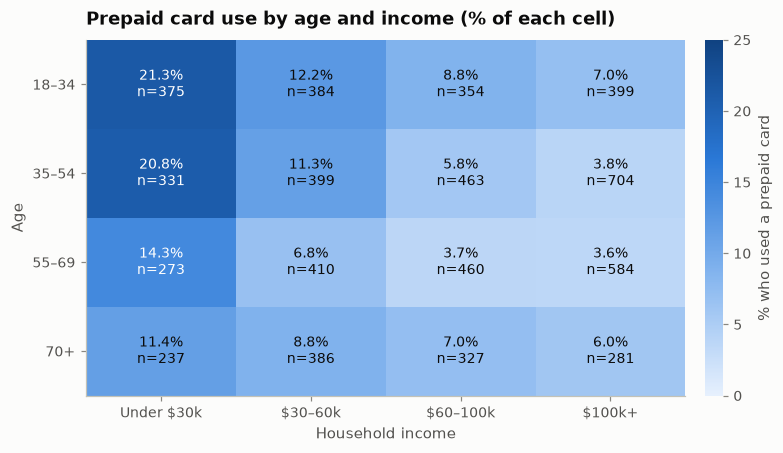

In [33]:
cell = view.groupby(["age_band", "income_band"])[TARGET].agg(["mean", "size"])
rate_grid = cell["mean"].unstack().loc[AGE_ORDER, INCOME_ORDER] * 100
n_grid = cell["size"].unstack().loc[AGE_ORDER, INCOME_ORDER]

fig, ax = plt.subplots(figsize=(7.6, 4.2))
im = ax.imshow(rate_grid, cmap=SEQ_CMAP, vmin=0, vmax=np.ceil(rate_grid.to_numpy().max() / 5) * 5, aspect="auto")
for i in range(rate_grid.shape[0]):
    for j in range(rate_grid.shape[1]):
        val = rate_grid.iloc[i, j]
        ax.text(j, i, f"{val:.1f}%\nn={n_grid.iloc[i, j]:,}", ha="center", va="center", fontsize=9,
                color="white" if val > 13 else INK)
ax.set_xticks(range(len(INCOME_ORDER)), INCOME_ORDER)
ax.set_yticks(range(len(AGE_ORDER)), AGE_ORDER)
ax.set_xlabel("Household income")
ax.set_ylabel("Age")
ax.grid(visible=False)
ax.set_title("Prepaid card use by age and income (% of each cell)")
cbar = fig.colorbar(im, ax=ax, fraction=0.045, pad=0.03)
cbar.set_label("% who used a prepaid card")
cbar.outline.set_visible(False)
fig.savefig(FIG_DIR / "11_age_by_income.png")
plt.show()

**Robustness to the oversamples.** The pooled data over-represents older adults and lower-income minority households (Section 2.2). The screening is repeated on the general-population sample alone to confirm the findings are not produced by the sample mix.

In [34]:
general = clean[clean["sample"] == 1]
assoc_general = association_table(general, CANDIDATES)
robust = assoc[["label", "cramers_v"]].rename(columns={"cramers_v": "V_all_samples"}).join(
    assoc_general["cramers_v"].rename("V_general_population_only"))
robust["rank_all"] = robust["V_all_samples"].rank(ascending=False).astype(int)
robust["rank_general"] = robust["V_general_population_only"].rank(ascending=False).astype(int)

rho = stats.spearmanr(robust["V_all_samples"], robust["V_general_population_only"])[0]
top20_all, top20_gen = set(robust.nsmallest(20, "rank_all").index), set(robust.nsmallest(20, "rank_general").index)
print(f"General-population sample: {len(general):,} respondents, usage rate {general[TARGET].mean():.1%}")
print(f"Rank correlation of association strength, all samples vs general population only: {rho:.2f}")
print(f"Variables in the top 20 under both views: {len(top20_all & top20_gen)} of 20")
display(fmt(robust.head(15), {"V_all_samples": "{:.3f}", "V_general_population_only": "{:.3f}"}))

inc_robust = pd.DataFrame({"All samples": rate_table(clean, "PPINCIMP")["rate"],
                           "General population only": rate_table(general, "PPINCIMP")["rate"]})
display(fmt(inc_robust, "{:.1%}"))

General-population sample: 4,977 respondents, usage rate 8.5%
Rank correlation of association strength, all samples vs general population only: 0.97
Variables in the top 20 under both views: 19 of 20


,label,V_all_samples,V_general_population_only,rank_all,rank_general
variable,,,,,
SAVINGSRANGES,How much money do you have in savings today...?,0.188,0.179,1,2
HARDSHIP_COUNT,Number of material hardships experienced sometimes or often (0-6),0.182,0.181,2,1
MATHARDSHIP_1,Worried whether food would run out before got money to buy more,0.177,0.176,3,3
KHscore,Knoll and Houts financial knowledge scale score,0.174,0.156,4,8
fpl,Poverty status,0.169,0.169,5,5
PPINCIMP,Household Income,0.168,0.171,6,4
MATHARDSHIP_2,Food didn't last and didn't have money to get more,0.166,0.166,7,6
PPETHM,Race / Ethnicity,0.166,0.142,8,15
ABSORBSHOCK,"Confidence in ability to raise $2,000 in 30 days",0.162,0.150,9,10


,All samples,General population only
"Less than $20,000",19.4%,18.6%
"$20,000–29,999",15.3%,17.4%
"$30,000–39,999",11.3%,10.6%
"$40,000–49,999",8.9%,8.9%
"$50,000–59,999",8.7%,8.4%
"$60,000–74,999",6.3%,5.6%
"$75,000–99,999",6.0%,5.4%
"$100,000–149,999",5.7%,5.6%
"$150,000 or more",3.5%,3.9%


**Takeaways**

- **Income and bank-account status are separate signals that stack.** In every income band, people reporting no account use prepaid cards two to three times as often as those with one: 27% vs 13% under \$30,000, and 12% vs 4% at \$100,000 or more. Low-income respondents with no account reported (n=398) are the highest-use segment found, at three times the overall rate.
- **Age and income also stack.** Use peaks at about 21% for under-55s with income below \$30,000 and falls to about 4% for 35–69-year-olds with income of \$100,000 or more. Age matters most at low incomes.
- **The findings hold without the oversamples.** On the general-population sample alone the association ranking is almost unchanged (rank correlation 0.97; 19 of the top 20 variables are the same) and the income gradient is nearly identical (18.6% falling to 3.9%).
- **Two signals are somewhat amplified by the oversamples:** race/ethnicity drops from 8th to 15th and the knowledge scores weaken slightly in the general population. They remain meaningful but should not be over-weighted.

---
# 5. Summary and hand-off to modelling

### What is now established

1. **The data is trustworthy.** It matches the official codebook on every variable, and every cleaning rule is documented and logged.
2. **Prepaid card use is a minority behaviour (8.8%) concentrated among financially fragile households**: low income, little or no savings, material hardship, no bank account, low financial knowledge. Younger adults and Black and Hispanic respondents use them more.
3. **Most users are nonetheless mainstream.** Two-thirds have a bank account and most have income above \$30,000, because the high-rate groups are small.
4. **Signals are modest individually and overlap heavily.** Prediction requires a combination of variables, chosen to cover different themes.

### Outputs handed to the next steps

| File | Contents |
|---|---|
| `data/cfpb_clean.csv` | Cleaned data: 6,367 respondents, 204 columns, non-answers as true missing values |
| `data/variable_roles.csv` | For every column: label, group, measurement type, role, missing rate |
| `figures/` | The 11 charts in this notebook as image files |

### Implications for modelling (Steps 5–8)

- **Feature selection (Step 5):** pick up to 20 from the 178 candidates, one representative per correlated cluster (Section 4.7), covering resources, strain, knowledge, banking and demographics.
- **Preparation (Step 6):** stratified train/test split; impute missing values, one-hot encode the unordered categories and standardise, all fitted on training data only.
- **Models and evaluation (Steps 7–8):** weight the classes for the 1-to-10 imbalance and judge models on recall, precision, precision-recall AUC and lift, not accuracy.

### Decisions needed before Step 5

1. **Other alternative-finance items** (`PRODUSE_1`, `2`, `4`, `5`): recommended **out** of the predictive model (Sections 3.3 and 4.5).
2. **Race / ethnicity:** relevant to the CFPB at-risk analysis; its use in a marketing-targeting model raises fair-lending concerns (Section 4.1).
3. **Non-response flags:** recommended to keep only `ABSORBSHOCK_NR` as a candidate; the savings and housing-cost flags carry no signal (Section 4.6).

### Limitations

- The survey is self-reported and was fielded in 2016; prepaid products and their users may have changed since.
- The outcome records whether a prepaid card was used, not how often, what it cost in fees, or why.
- All figures are unweighted, as the brief requires, so they describe this sample and are not national estimates.
- Everything in Section 4 is association, one variable at a time. It does not show that any characteristic causes prepaid card use.